# Me Conta: quais idosos têm mais chance de estar desconectados da internet?

## Global Solution 2026.2 · CitizenTech · IA & ML

### **Nicoli Amy Kassa | RM559104**

<br>

**O Problema**

Os avós guardam receitas, histórias da família e memórias do bairro que ninguém mais tem. Mas, quando
mandam um "bom dia" no grupo da família, recebem de volta um 👍 e nenhuma pergunta. E muitos nem chegam ao grupo da família: no
Brasil, **9,1 milhões de pessoas com 60 anos ou mais (uma em cada quatro) não usaram a internet** nos últimos três meses, e
**dois em cada três dizem que não sabiam usar** (em metade dos casos, quem respondeu foi outra pessoa; PNAD Contínua 2025, analisada neste notebook; os percentuais batem com a [divulgação do IBGE](https://agenciadenoticias.ibge.gov.br/pt/agencia-noticias/47408-proporcao-de-usuarios-da-internet-no-pais-ultrapassou-90-da-populacao-de-10-anos-ou-mais-em-2025.html)).

<br>

**A Solução**

O **Me Conta** é um aplicativo que troca o 👍 da família por uma pergunta que só a avó sabe responder. O neto
escolhe a pergunta, o app abre o WhatsApp com a mensagem pronta, a avó responde por áudio e a resposta vira uma página do
caderno da família.

O app cresce em três degraus:
1. **Conectar**: o modo "Ensine sua avó", para quem ainda está fora da
internet
2. **Aprofundar**: a pergunta, a resposta e o caderno
3. **Expandir**: o mapa de memórias do bairro

<br>

**O Objetivo da Matéria**

Treinar uma Rede Neural do tipo MLP (*Multi-Layer Perceptron*) que, a partir do perfil de uma pessoa de 60
anos ou mais (idade, escolaridade, renda, onde mora, com quem mora, se tem celular), estima a chance de ela **não ter usado
a internet nos últimos três meses**.

<br>

**Por que isso importa para o Me Conta?**

A pergunta pelo WhatsApp só chega a quem já está conectado. Para quem ainda está
fora, existe o degrau **Conectar**: o modo **"Ensine sua avó"** transforma quem já usa a internet em casa (o neto, a filha,
o cônjuge) em professor. Este modelo mostra **quem** são os idosos com mais chance de estar desconectados e **se eles moram
com alguém que já usa a internet**, para decidir onde e para quem o degrau Conectar deve chegar primeiro.

<br>

**Resultados em resumo:**

* **9,1 milhões de idosos desconectados (25,5%).** O risco é maior para quem tem 80 anos ou mais (59%), não tem instrução
  (59%), não tem celular próprio (84%), mora na zona rural (41%) ou no Nordeste (33%).
* **O modelo final é uma MLP pequena, com AUC de 0,943 no teste.** Ela foi escolhida pela regra de 1 erro-padrão
  entre combinações praticamente empatadas. Ponderado pela população, o modelo encontra mais de 8 em cada 10 idosos
  desconectados, e cerca de 3 em cada 4 que ele aponta estão de fato desconectados. Fica à frente da regressão logística
  e do Random Forest na validação cruzada, mas por pouco (cerca de 0,007 de AUC), e quase não sobreajusta: as AUCs de
  treino e de teste são praticamente iguais.
* **Ter alguém conectado em casa não basta.** Entre os desconectados, 4,9 milhões moram com alguém que usa a internet. No
  modelo, o que mais pesa é ter **celular próprio**: retreinado sem essa informação, ele perde bem mais AUC (cai para
  cerca de 0,88) do que sem a conexão dos outros moradores (cerca de 0,92). Morar com alguém conectado está associado a
  muito menos desconexão, mas não garante a conexão, e é aí que o Me Conta entra.
* **São dois públicos.** Dos 9,1 milhões, 5,9 milhões não têm celular próprio e 1,4 milhão têm celular sem internet:
  para eles, o primeiro passo é o acesso. Outros 1,8 milhão já têm celular com internet e ainda assim não usam: esse é o
  público do modo "Ensine sua avó" (seção 8).

<br>

**ODS**
- ODS 10: Redução das Desigualdades (meta 10.2, inclusão independentemente da idade)
- ODS 11: Cidades e Comunidades Sustentáveis (meta 11.4, memória do bairro)
- ODS 3: Saúde e Bem-Estar (meta 3.4, bem-estar pelo vínculo)

<br>

**Dados reais e públicos:** IBGE, PNAD Contínua 2025, 4º trimestre, módulo de Tecnologia da Informação e Comunicação
(TIC). Detalhes em `dados/README.md` e `dados/variaveis.md`.

<br>

**Roteiro:**

1. Problema e dados
2. Análise exploratória (ponderada pelo peso amostral do IBGE)
3. Preparação dos dados (sem vazamento)
4. Modelo: MLP em PyTorch e referências
5. Busca de hiperparâmetros: 12 combinações de 3 hiperparâmetros, validação cruzada só no treino
6. Resultados: treino × teste, gráficos e análise de overfitting
7. O que o modelo aprendeu
8. Conclusão para o cidadão

<br>

**Como executar:** O notebook roda do início ao fim sem intervenção (`Kernel → Restart & Run All`), em CPU ou GPU.
* **No Google Colab:** a primeira célula de código monta o Google Drive e, se o arquivo de dados ainda não existir, gera
  esse arquivo sozinha. Basta ajustar `PASTA_DRIVE` para a pasta do projeto no Drive.
* **Fora do Colab:** antes, gere o arquivo de dados com `python dados/extrair_pnadc.py`, a partir da pasta `ml/` (veja `dados/README.md`).

Dependências em `requirements.txt`. A flag `QUICK = True` reduz épocas e folds para um teste rápido do código; os
resultados apresentados foram obtidos com `QUICK = False`.

## Rodando no Google Colab

A célula abaixo só faz algo **no Colab** (fora dele, ela é ignorada). Ela monta o Google Drive, entra na pasta do projeto
(`PASTA_DRIVE`) e, se o arquivo de dados ainda não existir, roda o `dados/extrair_pnadc.py` para gerá-lo a partir do `.zip` do IBGE.
Ajuste `PASTA_DRIVE` se a pasta tiver outro nome.

In [1]:
import sys, os
PASTA_DRIVE = "/content/drive/MyDrive/FIAP - 2026/GS_CitizenTech/IA&ML"

if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir(PASTA_DRIVE)
    print("Pasta de trabalho:", os.getcwd())
    if os.path.exists("dados/processados/pnadc2025_tic_60mais.parquet"):
        print("Base processada encontrada: a extração não é necessária.")
    elif os.path.exists("dados/extrair_pnadc.py"):
        !python dados/extrair_pnadc.py
    else:
        print("Base processada e dados/extrair_pnadc.py não encontrados: confira PASTA_DRIVE.")

Mounted at /content/drive
Pasta de trabalho: /content/drive/MyDrive/FIAP - 2026/GS_CitizenTech/IA&ML
Base processada encontrada: a extração não é necessária.


## 0. Configuração do ambiente

**Escolhas e justificativas**

* **PyTorch**: controle explícito do laço de treino, registramos perda e AUC de treino e de
  validação a cada época para enxergar o overfitting.
* **Reprodutibilidade:** sementes fixas (`random`, `numpy`, `torch`) e `torch.use_deterministic_algorithms(True, warn_only=True)`, para que rodar de novo dê os mesmos resultados (na GPU, podem aparecer diferenças mínimas na 4ª casa decimal). Todas as combinações usam as mesmas sementes e os mesmos folds, o que torna a comparação justa. Mesmo assim, cada resultado vem de uma única semente por fold; por isso, diferenças menores que o desvio-padrão entre folds são tratadas como empate.
* **Por que uma MLP.** Para dados tabulares como estes, modelos de árvore (Random Forest, XGBoost) costumam ser tão bons
  quanto redes neurais, ou melhores, e um modelo linear muitas vezes fica perto. Escolhemos a MLP porque o treino época a
  época permite estudar o overfitting de forma explícita (curvas de treino × validação, dropout, número de épocas), que é
  parte central deste estudo. Para não depender só dessa escolha, a MLP é comparada, nos mesmos folds, com uma regressão
  logística e com um Random Forest.
* **Versões fixas:** a divisão em folds do `StratifiedGroupKFold` pode mudar entre versões do scikit-learn. As versões
  usadas estão em `requirements.txt` e são impressas na última célula. Os números apresentados foram obtidos no
  Google Colab com GPU T4; em CPU, podem variar na 4ª casa decimal.
* **Dados inteiros em memória (tensores)**, embaralhados com `torch.randperm` a cada época. A base tem algumas dezenas de
  milhares de linhas e cabe com folga na RAM.

In [2]:
import os, time, random, math, warnings
warnings.filterwarnings("ignore", category=FutureWarning)
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score, balanced_accuracy_score,
                             precision_score, recall_score, f1_score, confusion_matrix, roc_curve,
                             precision_recall_curve, classification_report)
import sklearn
from IPython.display import display, Markdown

# True = teste rápido do código; False = experimento completo
QUICK = False

SEED = 42
K_FOLDS = 3 if QUICK else 5
EPOCHS = 5 if QUICK else 30
BATCH_SIZE = 256

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(max(1, os.cpu_count() or 1))
torch.use_deterministic_algorithms(True, warn_only=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)

set_seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
pd.set_option("display.width", 200)
FIG_DIR = Path("dados/figuras")
FIG_DIR.mkdir(parents=True, exist_ok=True)

def salvar(fig, nome):
    # salva o gráfico em dados/figuras/NN_nome.png (os mesmos arquivos usados no relatório)
    fig.savefig(FIG_DIR / f"{nome}.png", dpi=150, bbox_inches="tight")

def br(x, casas=3):
    # número no formato brasileiro: 1.234,567
    return f"{x:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def pct(x, casas=1):
    return br(100 * x, casas) + "%"

print(f"PyTorch {torch.__version__} | scikit-learn {sklearn.__version__} | pandas {pd.__version__} | "
      f"dispositivo: {device} | QUICK={QUICK} | folds={K_FOLDS} | épocas={EPOCHS}")

PyTorch 2.14.1+cu130 | scikit-learn 1.6.1 | pandas 2.2.3 | dispositivo: cuda | QUICK=False | folds=5 | épocas=30


## 1. Problema e dados

**Pergunta de ML:** dado o perfil de uma pessoa de 60 anos ou mais, qual a chance de ela estar desconectada da internet?

* **Tipo de problema:** classificação binária.
* **Alvo:** `desconectado = 1` quando a pessoa respondeu **"Não"** à pergunta `S07001` da PNAD: *"Nos últimos três meses,
  utilizou a Internet em algum local?"*.
* **Unidade de análise:** pessoa de 60 anos ou mais que respondeu ao módulo TIC.

**Fonte:** IBGE, Pesquisa Nacional por Amostra de Domicílios Contínua (PNAD Contínua), microdados anuais do 4º trimestre de
2025, publicados em 02/07/2026, com o módulo suplementar de TIC. São dados **reais e públicos**, baixados de
`ftp.ibge.gov.br` (caminho completo em `dados/README.md`).

**Como a base foi gerada:** o script `dados/extrair_pnadc.py` lê o arquivo de largura fixa direto do `.zip`, usa as posições do
`input_PNADC_trimestre4_20251010.txt`, conta os moradores de cada domicílio (para saber, por exemplo, se mora um jovem que
usa internet), filtra as pessoas de 60+ e salva `dados/processados/pnadc2025_tic_60mais.parquet`.

**Peso amostral (`V1028`).** Cada pessoa da amostra representa milhares de brasileiros. Na **análise exploratória** os
números são **ponderados** pelo peso, para valerem para a população. No **treino do modelo** usamos as linhas sem peso: o
objetivo do modelo é aprender a relação entre perfil e desconexão, e não estimar um total da população.

In [3]:
CANDIDATOS = [Path("dados/processados/pnadc2025_tic_60mais.parquet"),
              Path("ml/dados/processados/pnadc2025_tic_60mais.parquet")]
ARQUIVO = next((p for p in CANDIDATOS if p.exists()), None)
if ARQUIVO is None:
    raise FileNotFoundError("Rode antes, na pasta ml/: python dados/extrair_pnadc.py (gera dados/processados/pnadc2025_tic_60mais.parquet)")

df = pd.read_parquet(ARQUIVO)

# Peso amostral
W = "V1028"

print(f"Arquivo: {ARQUIVO}")
print(f"Ano(s): {sorted(df['Ano'].unique())} | trimestre(s): {sorted(df['Trimestre'].unique())}")
print(f"Pessoas de 60+ na amostra: {len(df):,} | domicílios: {df['chave_domicilio'].nunique():,}")
print(f"População representada: {df[W].sum() / 1e6:.1f} milhões de pessoas de 60+")
print(f"Idade: {df['V2009'].min():.0f} a {df['V2009'].max():.0f} anos")
display(df.head())

Arquivo: dados/processados/pnadc2025_tic_60mais.parquet
Ano(s): ['2025'] | trimestre(s): ['4']
Pessoas de 60+ na amostra: 96,531 | domicílios: 71,022
População representada: 35.7 milhões de pessoas de 60+
Idade: 60 a 112 anos


,Ano,Trimestre,UF,Capital,RM_RIDE,UPA,Estrato,V1008,V1014,V2003,...,desconectado,outros_usam_internet,tem_outro_usuario_internet,tem_jovem_10a29,tem_jovem_que_usa_internet,outros_com_celular,mora_sozinho,urbano,faixa_etaria,regiao
0,2025,4,11,11,None,110000108,1110012,01,12,01,...,0,3,1,0,0,3.0000,0,1,80+,Norte
1,2025,4,11,11,None,110000108,1110012,03,12,01,...,0,0,0,0,0,0.0000,1,1,60-64,Norte
2,2025,4,11,11,None,110000108,1110012,05,12,01,...,0,0,0,0,0,0.0000,1,1,65-69,Norte
3,2025,4,11,11,None,110000108,1110012,06,12,01,...,0,2,1,1,1,2.0000,0,1,60-64,Norte
4,2025,4,11,11,None,110000108,1110012,07,12,02,...,0,1,1,0,0,1.0000,0,1,65-69,Norte


In [4]:
# Rótulos das categorias (dicionário da PNAD Contínua)
UF_SIGLA = {"11": "RO", "12": "AC", "13": "AM", "14": "RR", "15": "PA", "16": "AP", "17": "TO", "21": "MA",
            "22": "PI", "23": "CE", "24": "RN", "25": "PB", "26": "PE", "27": "AL", "28": "SE", "29": "BA",
            "31": "MG", "32": "ES", "33": "RJ", "35": "SP", "41": "PR", "42": "SC", "43": "RS", "50": "MS",
            "51": "MT", "52": "GO", "53": "DF"}
INSTRUCAO = {"1": "Sem instrução", "2": "Fund. incompleto", "3": "Fund. completo", "4": "Médio incompleto",
             "5": "Médio completo", "6": "Sup. incompleto", "7": "Sup. completo"}
RENDA_FAIXA = {"1": "até ¼ SM", "2": "¼ a ½ SM", "3": "½ a 1 SM", "4": "1 a 2 SM", "5": "2 a 3 SM",
               "6": "3 a 5 SM", "7": "mais de 5 SM"}
MOTIVO = {"1": "Serviço caro", "2": "Equipamento caro", "3": "Não disponível onde frequenta",
          "4": "Falta de necessidade", "5": "Falta de tempo", "6": "Não sabia usar",
          "7": "Privacidade ou segurança", "8": "Outro motivo"}
TIPO_AREA = {"1": "Capital", "2": "Resto da RM", "3": "Resto da RIDE", "4": "Interior"}
COR_RACA = {"1": "Branca", "2": "Preta", "3": "Amarela", "4": "Parda", "5": "Indígena"}
PAPEL = {"01": "Responsável", "02": "Cônjuge", "03": "Cônjuge", "08": "Pai/mãe/sogro(a) do responsável",
         "09": "Pai/mãe/sogro(a) do responsável"}

df["instrucao"] = pd.Categorical(df["VD3004"].map(INSTRUCAO), categories=list(INSTRUCAO.values()), ordered=True)
df["renda_faixa"] = pd.Categorical(df["VDI5009"].map(RENDA_FAIXA), categories=list(RENDA_FAIXA.values()), ordered=True)
df["uf"] = df["UF"].map(UF_SIGLA)
df["tem_celular"] = (df["S07006"] == "1").astype(int)

## 2. Análise exploratória

Todos os percentuais desta seção são **ponderados** pelo peso `V1028`, ou seja, valem para a população brasileira de 60 anos
ou mais. A coluna "n amostra" mostra quantas pessoas da amostra sustentam cada número.

In [5]:
def pct_ponderado(d, col, alvo="desconectado"):
    # % ponderado de desconectados por categoria de `col`
    t = d.assign(_wy=d[alvo] * d[W]).groupby(col, observed=True)[["_wy", W]].sum()
    return pd.DataFrame({"% desconectados": t["_wy"] / t[W] * 100,
                         "idosos (milhões)": t[W] / 1e6,
                         "n amostra": d.groupby(col, observed=True).size()})

pct_geral = np.average(df["desconectado"], weights=df[W]) * 100
print(f"Desconectados (ponderado): {pct_geral:.1f}% = {(df['desconectado'] * df[W]).sum() / 1e6:.1f} milhões de idosos")
print(f"Desconectados na amostra (sem peso): {df['desconectado'].mean() * 100:.1f}% "
      f"({df['desconectado'].sum():,} de {len(df):,})")

Desconectados (ponderado): 25.5% = 9.1 milhões de idosos
Desconectados na amostra (sem peso): 27.7% (26,737 de 96,531)


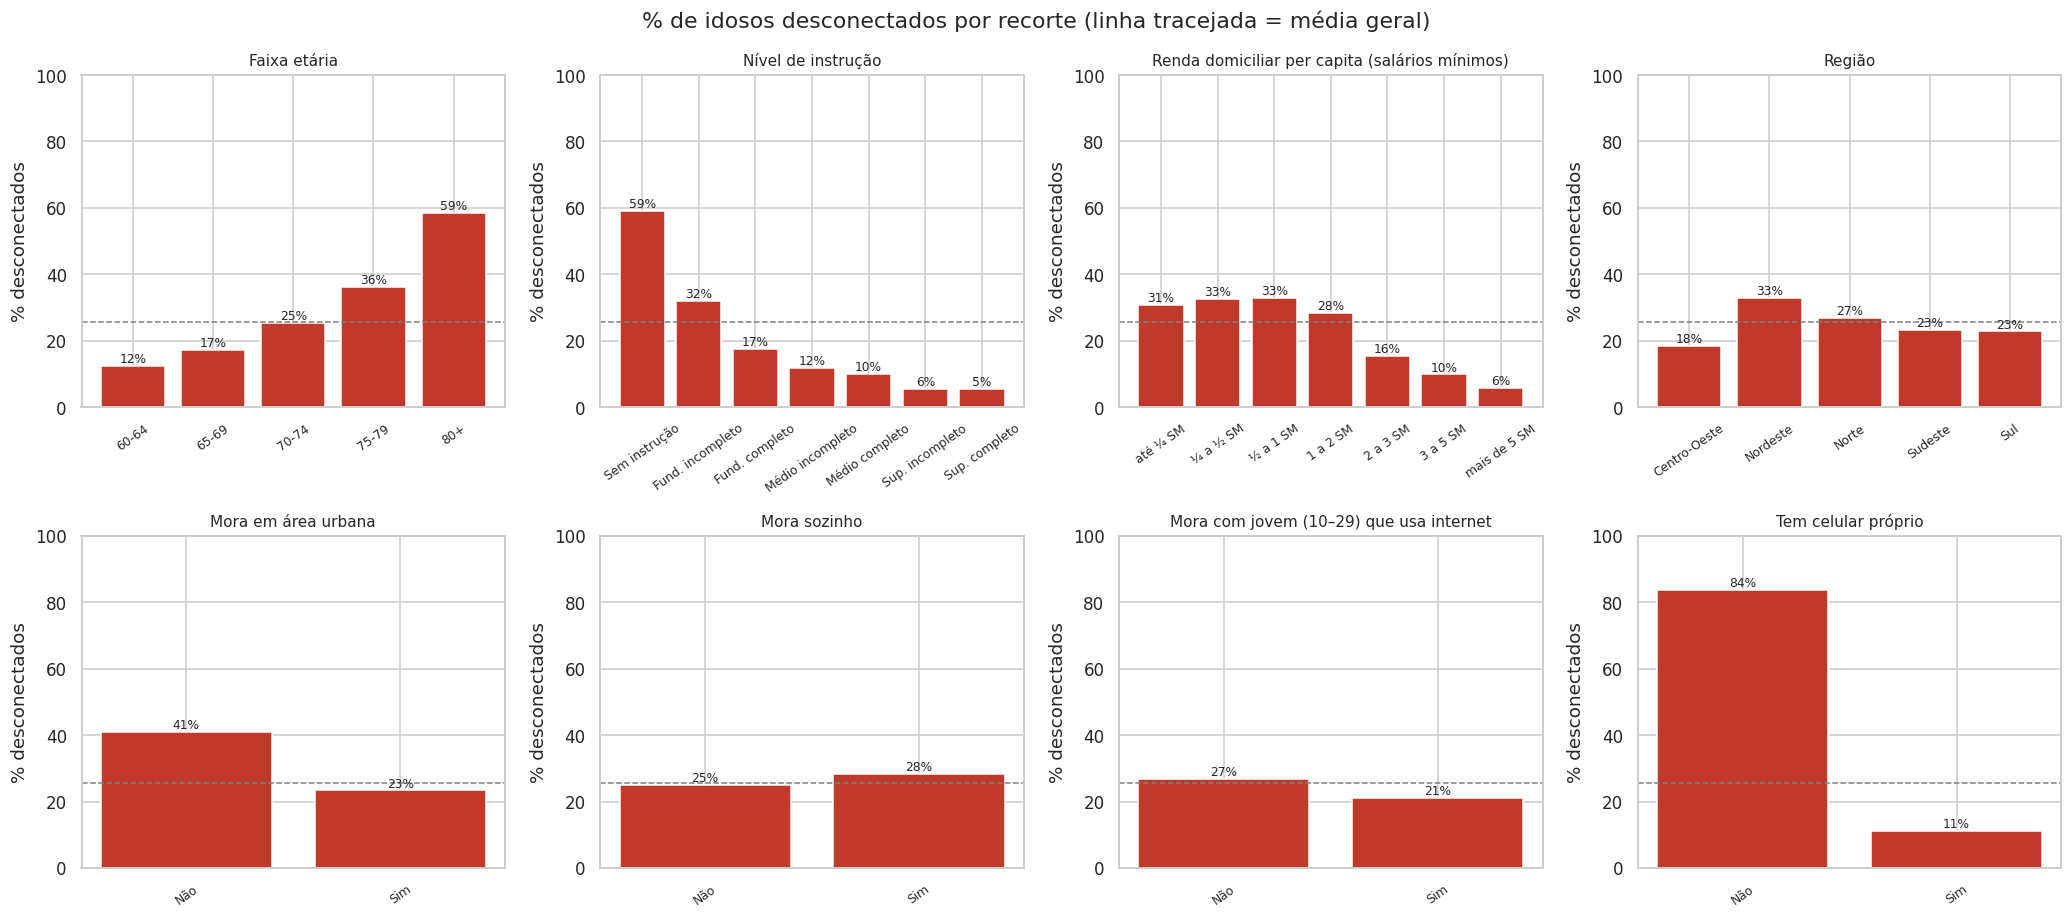

,% desconectados,idosos (milhões),n amostra
faixa_etaria,,,
60-64,12.3854,10.7572,28865
65-69,17.3100,8.7572,23536
70-74,25.2982,6.6044,17961
75-79,36.2369,4.5759,12363
80+,58.5097,5.0279,13806


,% desconectados,idosos (milhões),n amostra
instrucao,,,
Sem instrução,58.9785,4.4416,14758
Fund. incompleto,31.9154,15.4609,44030
Fund. completo,17.4614,2.8690,6990
Médio incompleto,11.9341,0.7759,1903
Médio completo,10.0928,6.5916,15650
Sup. incompleto,5.5081,0.5812,1296
Sup. completo,5.4797,5.0024,11904


,% desconectados,idosos (milhões),n amostra
renda_faixa,,,
até ¼ SM,30.7017,1.0287,2947
¼ a ½ SM,32.6943,1.8975,5325
½ a 1 SM,32.9943,7.9662,22005
1 a 2 SM,28.2651,16.0534,44556
2 a 3 SM,15.5342,4.0304,10101
3 a 5 SM,9.8577,2.6228,6399
mais de 5 SM,5.8912,2.0925,5100


In [6]:
RECORTES = [("faixa_etaria", "Faixa etária"), ("instrucao", "Nível de instrução"),
            ("renda_faixa", "Renda domiciliar per capita (salários mínimos)"), ("regiao", "Região"),
            ("urbano", "Mora em área urbana"), ("mora_sozinho", "Mora sozinho"),
            ("tem_jovem_que_usa_internet", "Mora com jovem (10–29) que usa internet"),
            ("tem_celular", "Tem celular próprio")]
fig, axes = plt.subplots(2, 4, figsize=(19, 8.5))
TABELAS_EDA = {}
for ax, (col, titulo) in zip(axes.ravel(), RECORTES):
    t = pct_ponderado(df, col)
    if set(t.index) <= {0, 1}:
        t.index = t.index.map({0: "Não", 1: "Sim"})
    TABELAS_EDA[col] = t
    ax.bar(t.index.astype(str), t["% desconectados"], color="#c0392b")
    ax.axhline(pct_geral, color="gray", ls="--", lw=1)
    for i, v in enumerate(t["% desconectados"]):
        ax.text(i, v + 1, f"{v:.0f}%", ha="center", fontsize=8)
    ax.set_title(titulo, fontsize=10); ax.set_ylabel("% desconectados"); ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=35, labelsize=8)
fig.suptitle("% de idosos desconectados por recorte (linha tracejada = média geral)"); plt.tight_layout(); salvar(fig, "01_eda_recortes"); plt.show()
for col, _ in RECORTES[:3]:
    display(TABELAS_EDA[col])

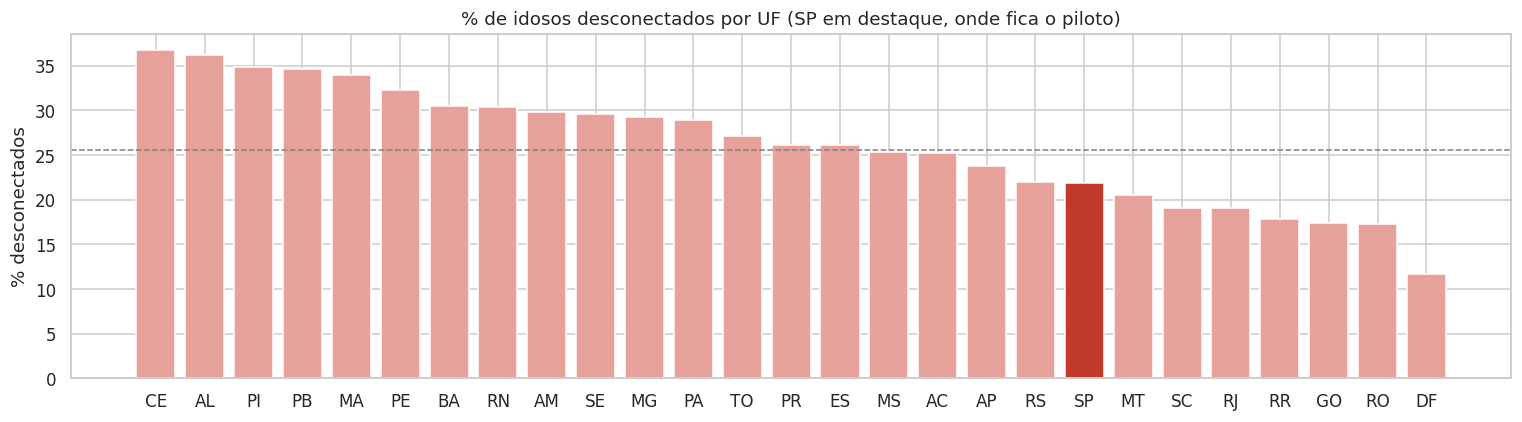

Município de São Paulo: 20.9% desconectados (440 mil idosos; n amostra = 1,813)


In [7]:
t_uf = pct_ponderado(df, "uf").sort_values("% desconectados", ascending=False)
fig, ax = plt.subplots(figsize=(14, 4))
cores = ["#c0392b" if u == "SP" else "#e6a19a" for u in t_uf.index]
ax.bar(t_uf.index, t_uf["% desconectados"], color=cores)
ax.axhline(pct_geral, color="gray", ls="--", lw=1)
ax.set_ylabel("% desconectados"); ax.set_title("% de idosos desconectados por UF (SP em destaque, onde fica o piloto)")
plt.tight_layout(); salvar(fig, "02_eda_uf"); plt.show()

sp = df[df["Capital"] == "35"]
if len(sp):
    print(f"Município de São Paulo: {np.average(sp['desconectado'], weights=sp[W]) * 100:.1f}% desconectados "
          f"({(sp['desconectado'] * sp[W]).sum() / 1e3:,.0f} mil idosos; n amostra = {len(sp):,})")

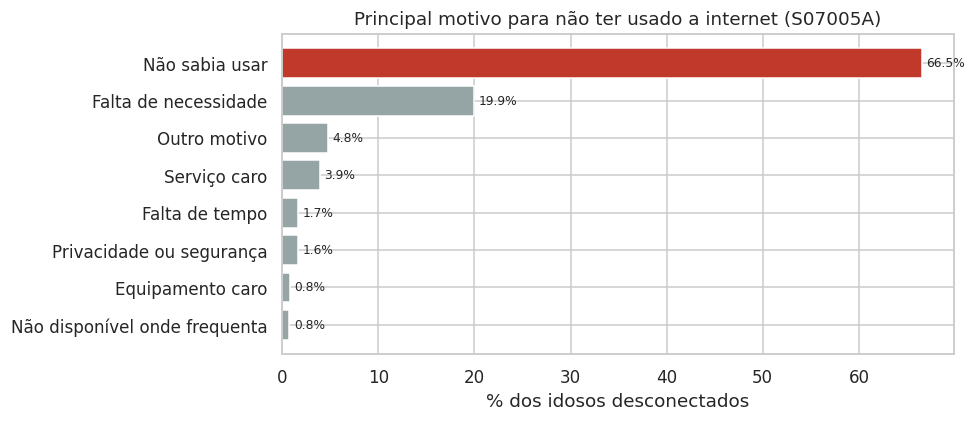

Entre os idosos DESCONECTADOS (ponderado):
  moram com um jovem de 10 a 29 anos que usa internet: 19.5%
  moram com alguém (qualquer idade) que usa internet:  53.8%
  moram sozinhos:                                      20.6%
  têm celular próprio:                                 35.3%
    • com internet no celular (S07007 = 1):             19.5%
    • sem internet no celular (S07007 = 2):             15.8%
  entre os que têm celular, % com internet no aparelho: 55.2%
  módulo respondido por outra pessoa (S07009 = 2 ou 3): 51.9%
  'não sabia usar' quando respondeu a própria pessoa: 63.1%
  'não sabia usar' quando respondeu outra pessoa: 69.7%
  trocaram mensagens por WhatsApp etc. (S07005B2):     10.2%


In [8]:
# Só entre os desconectados: por que não usam e com quem moram
desc = df[df["desconectado"] == 1]
mot = (desc.assign(motivo=desc["S07005A"].map(MOTIVO)).groupby("motivo")[W].sum() / desc[W].sum() * 100)
mot = mot.sort_values()
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(mot.index, mot.values, color=["#c0392b" if m == "Não sabia usar" else "#95a5a6" for m in mot.index])
for i, v in enumerate(mot.values):
    ax.text(v + .5, i, f"{v:.1f}%", va="center", fontsize=8)
ax.set_xlabel("% dos idosos desconectados"); ax.set_title("Principal motivo para não ter usado a internet (S07005A)")
plt.tight_layout(); salvar(fig, "03_eda_motivos"); plt.show()

def pct_w(mask):
    return (desc.loc[mask, W].sum() / desc[W].sum()) * 100

print("Entre os idosos DESCONECTADOS (ponderado):")
print(f"  moram com um jovem de 10 a 29 anos que usa internet: {pct_w(desc['tem_jovem_que_usa_internet'] == 1):.1f}%")
print(f"  moram com alguém (qualquer idade) que usa internet:  {pct_w(desc['outros_usam_internet'] > 0):.1f}%")
print(f"  moram sozinhos:                                      {pct_w(desc['mora_sozinho'] == 1):.1f}%")
print(f"  têm celular próprio:                                 {pct_w(desc['tem_celular'] == 1):.1f}%")
print(f"    • com internet no celular (S07007 = 1):             {pct_w((desc['tem_celular'] == 1) & (desc['S07007'] == '1')):.1f}%")
print(f"    • sem internet no celular (S07007 = 2):             {pct_w((desc['tem_celular'] == 1) & (desc['S07007'] == '2')):.1f}%")
com_cel = desc[desc["tem_celular"] == 1]
print(f"  entre os que têm celular, % com internet no aparelho: "
      f"{com_cel.loc[com_cel['S07007'] == '1', W].sum() / com_cel[W].sum() * 100:.1f}%")
print(f"  módulo respondido por outra pessoa (S07009 = 2 ou 3): {pct_w(desc['S07009'].isin(['2', '3'])):.1f}%")
for quem, cod in [("a própria pessoa", ["1"]), ("outra pessoa", ["2", "3"])]:
    sub = desc[desc["S07009"].isin(cod)]
    print(f"  'não sabia usar' quando respondeu {quem}: "
          f"{sub.loc[sub['S07005A'] == '6', W].sum() / sub[W].sum() * 100:.1f}%")
print(f"  trocaram mensagens por WhatsApp etc. (S07005B2):     {pct_w(desc['S07005B2'] == '1'):.1f}%")

**Análise exploratória**

* **Tamanho do problema.** A amostra tem **96.531 pessoas de 60+** em 71.022 domicílios, que representam **35,7 milhões**
  de brasileiros. Desses, **25,5% (9,1 milhões)** não usaram a internet nos últimos três meses. O percentual é o complemento dos 74,5% de idosos usuários que o
  [IBGE divulgou para a PNAD TIC 2025](https://agenciadenoticias.ibge.gov.br/pt/agencia-noticias/47408-proporcao-de-usuarios-da-internet-no-pais-ultrapassou-90-da-populacao-de-10-anos-ou-mais-em-2025.html), o que confirma que a extração e o uso do peso estão corretos.
* **Idade.** A desconexão sobe a cada faixa: **12% aos 60–64, 17%, 25%, 36% e 59% aos 80+**. Quem tem 80 anos ou mais tem
  quase **5 vezes** mais chance de estar fora do que quem tem 60–64.
* **Escolaridade.** É o recorte com a maior diferença: **59% entre os sem instrução** contra **5,5% entre os com superior
  completo** (11 vezes). O grupo mais numeroso, fundamental incompleto (15,5 milhões de idosos), tem 32% de desconectados.
* **Renda.** Até 1 salário mínimo per capita a desconexão fica estável, entre **31% e 33%**. Ela só cai de verdade a partir
  de 2 SM (**16%**) e chega a **6%** acima de 5 SM. Ou seja, a renda pesa, mas o degrau mais forte é a escolaridade.
* **Território.** O **Nordeste** tem a maior taxa (**33%**) e o **Centro-Oeste** a menor (**18%**). Entre as UFs, vai de
  **37% no Ceará** e 36% em Alagoas até **12% no Distrito Federal**. Na **zona rural**, **41%** estão desconectados, contra
  **23%** na urbana. São Paulo fica abaixo da média (22%), mas, por ser grande, o **município de São Paulo** ainda soma
  **440 mil idosos desconectados (20,9%)**.
* **Com quem mora.** Quem **mora sozinho** está só um pouco mais desconectado (**28%** contra 25%). Quem **mora com um
  jovem de 10 a 29 anos que usa internet** está menos (**21%** contra 27%). Ter alguém conectado em casa está associado a
  menos desconexão, mas não garante a conexão.
* **Celular.** É a diferença mais forte: **84%** dos idosos sem celular próprio estão desconectados, contra **11%** dos
  que têm.
* **Motivos.** Entre os desconectados, **66,5%** dizem que **não sabiam usar** (o mesmo número [divulgado pelo IBGE](https://agenciadenoticias.ibge.gov.br/pt/agencia-noticias/47408-proporcao-de-usuarios-da-internet-no-pais-ultrapassou-90-da-populacao-de-10-anos-ou-mais-em-2025.html)) e
  **20%** citam falta de necessidade. Preço do serviço, preço do aparelho e falta de acesso, somados, ficam abaixo de
  **6%**. Atenção: em **52%** dos desconectados, quem respondeu o módulo foi **outra
  pessoa** (em geral, outro morador), e não o próprio idoso. O motivo pode refletir, em parte, a visão da família.
  Mesmo assim, "não sabia usar" aparece nos dois casos: **63%** quando o próprio idoso respondeu e **70%** quando outra
  pessoa respondeu por ele.
* **Com quem moram e o que têm.** Entre os 9,1 milhões de desconectados:
  * **54% (4,9 milhões)** moram com **alguém que usa internet**;
  * **19% (1,8 milhão)** moram com um **jovem que usa internet**, o "neto professor";
  * **35% (3,2 milhões)** **já têm celular próprio**, mas nem todos com internet: **19,5%** dos desconectados têm
    internet no celular e **15,8%** não têm. Ou seja, entre os desconectados com celular, **55%** têm internet no
    aparelho e **45%** não têm;
  * **21% (1,9 milhão)** **moram sozinhos** e precisam de um caminho que venha de fora de casa;
  * só **10%** trocaram mensagens por WhatsApp.

  Há, portanto, dois públicos diferentes: quem não tem o aparelho ou a conexão, e quem já tem os dois e ainda assim não
  usa. Só o segundo depende de aprender (seção 8).
* **Desbalanceamento.** Na amostra, **27,7%** são desconectados (2,6 conectados para cada desconectado). Isso justifica
  o `pos_weight` e o uso da AUC na seção 3.
* **Tendência.** Segundo o [IBGE](https://agenciadenoticias.ibge.gov.br/pt/agencia-noticias/47408-proporcao-de-usuarios-da-internet-no-pais-ultrapassou-90-da-populacao-de-10-anos-ou-mais-em-2025.html), a proporção de idosos que usam a internet subiu de 70,1% em 2024 para 74,5% em 2025, ou seja, a desconexão vem caindo.

## 3. Preparação dos dados

### 3.1 Variáveis explicativas e o que ficou de fora

| Grupo | Variáveis (nome no modelo ← código PNAD) | Tratamento |
|---|---|---|
| Numéricas | `idade` ← V2009, `anos_estudo` ← VD3005, `log_renda_pc` ← log(1 + VDI5008), `n_moradores` ← VD2003, `outros_usam_internet`, `outros_com_celular` | mediana para faltantes + padronização |
| Binárias (0/1) | `mulher` ← V2007, `sabe_ler` ← V3001, `aposentado` ← VI5004A, `trabalha` ← VD4002, `tem_celular` ← S07006, `tem_computador` ← S01028, `sinal_celular_ok` ← S01030C, `mora_sozinho` ← VD2004, `urbano` ← V1022, `tem_jovem_10a29`, `tem_jovem_que_usa_internet` | 1 = sim, 0 = não; "ignorado" e "não sabe" viram ausentes e recebem a moda do treino |
| Categóricas | `uf` ← UF, `tipo_area` ← V1023, `cor_raca` ← V2010, `papel_no_domicilio` ← V2005 | moda para faltantes + *one-hot* |

*Como as binárias são codificadas:* cada código da PNAD é mapeado explicitamente. "Sim" vira 1, "não" vira 0, e os
códigos sem resposta útil viram ausentes: `9 = ignorado` em `aposentado` (VI5004A) e `3 = não sabe` em `sinal_celular_ok`
(S01030C). Esses ausentes são preenchidos com a moda calculada no treino. Em `trabalha`, quem está fora da força de
trabalho (VD4001 = 2) conta como 0, porque isso é uma informação ("não trabalha"), e não um dado faltante. A célula abaixo
mostra quantos ausentes cada binária tem antes da imputação.

*Por que a renda entra em log:* a renda é muito assimétrica (poucas pessoas com valores muito altos). O log aproxima a
distribuição de algo simétrico, e a padronização passa a funcionar bem.

*Por que as variáveis do domicílio contam só os **outros** moradores:* se a pessoa usasse a internet e entrasse na contagem,
a variável "carregaria" a resposta. Por isso o script de extração desconta a própria pessoa.

**Variáveis excluídas por vazamento de dados (*data leakage*).** Algumas perguntas do questionário só são feitas para quem
usou a internet (ou só para quem não usou). Se entrassem no modelo, o simples fato de estarem preenchidas entregaria a
resposta:

| Código | Pergunta | Por que sai |
|---|---|---|
| S07001A, S07002x, S07004x | frequência de uso, aparelhos, atividades na internet | só para quem usou |
| S07005A, S07005Bx | motivo de não ter usado, uso de WhatsApp etc. | só para quem não usou (usadas só na exploração) |
| S07007 | o celular tem acesso à internet | praticamente o próprio alvo |
| S01029, S01030D | domicílio tem internet / motivo de não ter | para quem mora sozinho, é o próprio alvo |

In [9]:
def binaria(serie, sim=("1",), nao=("2",)):
    # 1 = sim, 0 = não; qualquer outro código (ignorado, não sabe, vazio) vira ausente (NaN) para o imputador
    s = serie.astype("string")
    return pd.Series(np.where(s.isin(sim), 1.0, np.where(s.isin(nao), 0.0, np.nan)), index=serie.index)

def montar_features(d):
    X = pd.DataFrame(index=d.index)
    # numéricas
    X["idade"] = d["V2009"]
    X["anos_estudo"] = pd.to_numeric(d["VD3005"], errors="coerce")
    X["log_renda_pc"] = np.log1p(d["VDI5008"])
    X["n_moradores"] = d["VD2003"]
    X["outros_usam_internet"] = d["outros_usam_internet"]
    X["outros_com_celular"] = d["outros_com_celular"]
    # binárias (códigos da PNAD mapeados um a um)
    X["mulher"] = binaria(d["V2007"], sim=("2",), nao=("1",))
    X["sabe_ler"] = binaria(d["V3001"])
    X["aposentado"] = binaria(d["VI5004A"])                 # 9 = ignorado → ausente
    trab = binaria(d["VD4002"])                             # 1 = ocupado, 2 = desocupado
    fora = np.where(d["VD4001"] == "2", 0.0, np.nan)        # fora da força de trabalho = não trabalha
    X["trabalha"] = trab.where(trab.notna(), fora)
    X["tem_celular"] = binaria(d["S07006"])
    X["tem_computador"] = binaria(d["S01028"])
    X["sinal_celular_ok"] = binaria(d["S01030C"])           # 3 = não sabe → ausente
    for c in ["mora_sozinho", "urbano", "tem_jovem_10a29", "tem_jovem_que_usa_internet"]:
        X[c] = d[c].astype(float)
    # categóricas
    X["uf"] = d["UF"].map(UF_SIGLA)
    X["tipo_area"] = d["V1023"].map(TIPO_AREA)
    X["cor_raca"] = d["V2010"].map(COR_RACA)
    X["papel_no_domicilio"] = d["V2005"].map(PAPEL).fillna("Outro")
    return X

NUM = ["idade", "anos_estudo", "log_renda_pc", "n_moradores", "outros_usam_internet", "outros_com_celular"]
BIN = ["mulher", "sabe_ler", "aposentado", "trabalha", "tem_celular", "tem_computador", "sinal_celular_ok",
       "mora_sozinho", "urbano", "tem_jovem_10a29", "tem_jovem_que_usa_internet"]
CAT = ["uf", "tipo_area", "cor_raca", "papel_no_domicilio"]

X_df = montar_features(df)
y = df["desconectado"].to_numpy().astype(np.float32)
grupos = df["chave_domicilio"].to_numpy()
print(f"{X_df.shape[1]} variáveis: {len(NUM)} numéricas, {len(BIN)} binárias, {len(CAT)} categóricas")

print("\nCódigos originais das variáveis com respostas especiais (contagem na amostra):")
for col in ["VI5004A", "S01030C", "VD4001", "VD4002"]:
    print(f"  {col}: {df[col].fillna('vazio').value_counts().sort_index().to_dict()}")

print("\n% de ausentes por variável antes da imputação (só as que têm):")
falt = X_df.isna().mean().mul(100).round(3)
if (falt > 0).any():
    display(falt[falt > 0].to_frame("% ausentes"))
else:
    print("  nenhuma variável com ausentes")
display(X_df.describe(include="all").T[["count", "unique", "mean", "std", "min", "max"]])

21 variáveis: 6 numéricas, 11 binárias, 4 categóricas

Códigos originais das variáveis com respostas especiais (contagem na amostra):
  VI5004A: {'1': 68248, '2': 28221, '9': 62}
  S01030C: {'1': 82822, '2': 12522, '3': 1187}
  VD4001: {'1': 24337, '2': 72194}
  VD4002: {'1': 23889, '2': 448, 'vazio': 72194}

% de ausentes por variável antes da imputação (só as que têm):


,% ausentes
log_renda_pc,0.1020
aposentado,0.0640
sinal_celular_ok,1.2300
cor_raca,0.0110


,count,unique,mean,std,min,max
idade,96531.0000,NaN,70.1856,8.1203,60.0000,112.0000
anos_estudo,96531.0000,NaN,6.9989,5.2169,0.0000,16.0000
log_renda_pc,96433.0000,NaN,7.4264,1.2680,0.0000,12.7817
n_moradores,96531.0000,NaN,2.4571,1.2653,1.0000,14.0000
outros_usam_internet,96531.0000,NaN,1.1463,1.0919,0.0000,10.0000
outros_com_celular,96531.0000,NaN,1.1659,1.0637,0.0000,9.0000
mulher,96531.0000,NaN,0.5453,0.4980,0.0000,1.0000
sabe_ler,96531.0000,NaN,0.8241,0.3807,0.0000,1.0000
aposentado,96469.0000,NaN,0.7075,0.4549,0.0000,1.0000
trabalha,96531.0000,NaN,0.2475,0.4315,0.0000,1.0000


### 3.2 Divisão treino / teste por domicílio

* **80% treino e 20% teste**, **estratificados** pelo alvo (a proporção de desconectados é a mesma nos dois).
* **Separados por domicílio** (`StratifiedGroupKFold` com a chave do domicílio): duas pessoas da mesma casa (por exemplo, um
  casal de idosos) ficam sempre do mesmo lado. Elas compartilham as variáveis do domicílio e costumam ter o mesmo
  comportamento; se uma estivesse no treino e a outra no teste, o teste ficaria otimista.
* O **teste só é usado no fim**, para relatar o resultado. Toda escolha (hiperparâmetros, número de épocas) é feita com
  validação cruzada **dentro do treino**.

In [10]:
divisor = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
idx_treino, idx_teste = next(divisor.split(X_df, y, grupos))
Xtr_df, Xte_df = X_df.iloc[idx_treino], X_df.iloc[idx_teste]
y_tr, y_te = y[idx_treino], y[idx_teste]
g_tr = grupos[idx_treino]

assert not set(grupos[idx_treino]) & set(grupos[idx_teste]), "domicílio nos dois lados!"
print(f"Treino: {len(idx_treino):,} pessoas ({len(idx_treino) / len(y):.0%}) | desconectados: {y_tr.mean():.1%}")
print(f"Teste:  {len(idx_teste):,} pessoas ({len(idx_teste) / len(y):.0%}) | desconectados: {y_te.mean():.1%}")
print("Nenhum domicílio aparece nos dois conjuntos.")

Treino: 77,159 pessoas (80%) | desconectados: 27.6%
Teste:  19,372 pessoas (20%) | desconectados: 28.1%
Nenhum domicílio aparece nos dois conjuntos.


### 3.3 Pré-processamento sem vazamento e desbalanceamento

* O pré-processamento (mediana, moda, média e desvio da padronização, categorias do *one-hot*) é **ajustado só nos dados de
  treino** de cada etapa e depois aplicado aos dados de validação ou teste. Estatísticas do teste nunca entram no treino.
* **Desbalanceamento:** como "desconectado" é a classe minoritária, um modelo que previsse sempre "conectado" já teria
  acurácia alta e seria inútil. Por isso:
  * A perda usa `pos_weight = nº de conectados / nº de desconectados` (`BCEWithLogitsLoss`), o que dá o mesmo peso
    total às duas classes;
  * A métrica de escolha é a **AUC-ROC**, que não depende do limiar e não é enganada pelo desbalanceamento. Também
    relatamos recall, precisão, F1 e acurácia balanceada.

In [11]:
def novo_preprocessador(num=NUM, bin_=BIN, cat=CAT):
    return ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num),
        ("bin", SimpleImputer(strategy="most_frequent"), bin_),
        ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                              OneHotEncoder(handle_unknown="ignore", sparse_output=False)), cat),
    ])

def para_tensor(a):
    return torch.tensor(np.asarray(a, dtype=np.float32), device=device)

pre_demo = novo_preprocessador().fit(Xtr_df)
print(f"Depois do one-hot: {len(pre_demo.get_feature_names_out())} colunas de entrada na rede")
print(f"pos_weight no treino = {(1 - y_tr.mean()) / y_tr.mean():.2f}")

Depois do one-hot: 57 colunas de entrada na rede
pos_weight no treino = 2.62


## 4. Modelo: MLP em PyTorch

* **Arquitetura:** `Linear → ReLU (→ Dropout)` para cada camada oculta e uma camada de saída `Linear(…, 1)` que devolve um
  *logit*. Nas camadas ocultas,
  usamos **ReLU** em vez de sigmoide, porque ela evita a saturação do gradiente.
* **Perda:** `BCEWithLogitsLoss` com `pos_weight` (aplica a sigmoide internamente, de forma numericamente estável).
* **Otimizador:** Adam, mini-batches de 256.
* **Métricas por época:** perda e AUC em treino e validação, em modo `eval` (sem dropout), para a comparação treino ×
  validação ser justa.
* **Previsão:** `sigmoid(logit)` = probabilidade de estar desconectado; limiar 0,5.

In [12]:
class MLP(nn.Module):
    def __init__(self, in_dim, hidden, dropout=0.0):
        super().__init__()
        layers, d = [], in_dim
        for h in hidden:
            layers += [nn.Linear(d, h), nn.ReLU()]
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            d = h
        # 1 logit → BCEWithLogitsLoss
        layers.append(nn.Linear(d, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

def n_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

@torch.no_grad()
def avaliar(model, X, y, pos_weight):
    model.eval()
    logits = model(X)
    loss = F.binary_cross_entropy_with_logits(logits, y, pos_weight=pos_weight).item()
    proba = torch.sigmoid(logits).squeeze(1).cpu().numpy()
    return loss, roc_auc_score(y.cpu().numpy().ravel(), proba), proba

def treinar(X_tr, y_tr, X_va=None, y_va=None, hidden=(64, 32), lr=1e-3, dropout=0.0,
            epochs=EPOCHS, batch_size=BATCH_SIZE, seed=SEED, verbose=False):
    set_seed(seed)
    model = MLP(X_tr.shape[1], hidden, dropout).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    n_pos = y_tr.sum()
    pos_weight = ((len(y_tr) - n_pos) / n_pos).reshape(1)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    gen = torch.Generator().manual_seed(seed)
    hist = {k: [] for k in ["train_loss", "train_auc", "val_loss", "val_auc"]}
    for ep in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(X_tr), generator=gen).to(device)
        for i in range(0, len(X_tr), batch_size):
            idx = perm[i:i + batch_size]
            loss = criterion(model(X_tr[idx]), y_tr[idx])
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
        tl, ta, _ = avaliar(model, X_tr, y_tr, pos_weight)
        hist["train_loss"].append(tl); hist["train_auc"].append(ta)
        if X_va is not None:
            vl, va, _ = avaliar(model, X_va, y_va, pos_weight)
            hist["val_loss"].append(vl); hist["val_auc"].append(va)
        if verbose:
            extra = f" | validação: perda {vl:.4f} AUC {va:.4f}" if X_va is not None else ""
            print(f"  época {ep:2d} | treino: perda {tl:.4f} AUC {ta:.4f}{extra}")
    return model, hist, pos_weight

@torch.no_grad()
def prever_df(model, pre, Xd):
    # Probabilidade de estar desconectado, a partir de um DataFrame de variáveis e do pré-processador ajustado
    model.eval()
    return torch.sigmoid(model(para_tensor(pre.transform(Xd)))).squeeze(1).cpu().numpy()

def metricas(y_true, proba, limiar=0.5, w=None):
    # w = peso amostral (V1028); sem w, as métricas descrevem a amostra
    pred = (proba >= limiar).astype(int)
    return {"AUC": roc_auc_score(y_true, proba, sample_weight=w),
            "PR-AUC": average_precision_score(y_true, proba, sample_weight=w),
            "acurácia": accuracy_score(y_true, pred, sample_weight=w),
            "acurácia balanceada": balanced_accuracy_score(y_true, pred, sample_weight=w),
            "precisão": precision_score(y_true, pred, zero_division=0, sample_weight=w),
            "recall": recall_score(y_true, pred, zero_division=0, sample_weight=w),
            "F1": f1_score(y_true, pred, zero_division=0, sample_weight=w)}

### 4.1 Folds de validação cruzada (só no treino)

O treino é dividido em **K folds estratificados e agrupados por domicílio**. Para cada fold, o pré-processador é ajustado
nos K−1 folds de treino e aplicado ao fold de validação. Os folds são preparados uma vez e reaproveitados por todas as
combinações de hiperparâmetros, para que todas sejam comparadas exatamente nos mesmos dados.

In [13]:
cv = StratifiedGroupKFold(n_splits=K_FOLDS, shuffle=True, random_state=SEED)
FOLDS = []
for k, (f_tr, f_va) in enumerate(cv.split(Xtr_df, y_tr, g_tr)):
    pre = novo_preprocessador().fit(Xtr_df.iloc[f_tr])
    FOLDS.append(dict(
        Xa=para_tensor(pre.transform(Xtr_df.iloc[f_tr])), ya=para_tensor(y_tr[f_tr]).view(-1, 1),
        Xb=para_tensor(pre.transform(Xtr_df.iloc[f_va])), yb=para_tensor(y_tr[f_va]).view(-1, 1),
        ya_np=y_tr[f_tr], yb_np=y_tr[f_va], Xa_np=pre.transform(Xtr_df.iloc[f_tr]), Xb_np=pre.transform(Xtr_df.iloc[f_va]),
        idx_tr=f_tr, idx_va=f_va, nomes=list(pre.get_feature_names_out())))
    print(f"fold {k + 1}: treino {len(f_tr):,} | validação {len(f_va):,} | desconectados na validação {y_tr[f_va].mean():.1%}")

fold 1: treino 61,725 | validação 15,434 | desconectados na validação 27.1%
fold 2: treino 61,673 | validação 15,486 | desconectados na validação 28.2%
fold 3: treino 61,730 | validação 15,429 | desconectados na validação 28.3%
fold 4: treino 61,789 | validação 15,370 | desconectados na validação 27.2%
fold 5: treino 61,719 | validação 15,440 | desconectados na validação 27.2%


### 4.2 Referências (baselines)

Antes da MLP, cinco referências e uma MLP simples, avaliadas **nos mesmos folds** mostram se a rede está de fato acrescentando algo:

* **Modelo ingênuo:** sempre prevê "conectado" (a classe majoritária). Mostra por que acurácia sozinha engana.
* **Regressão logística** (`class_weight="balanced"`): o modelo linear clássico para classificação binária. Se a MLP não
  passar dela, a não linearidade não está ajudando.
* **Random Forest** (300 árvores, `min_samples_leaf=20`, `class_weight="balanced_subsample"`): representa os modelos de
  árvore, que costumam ir bem em dados tabulares. Ele não passa por busca de hiperparâmetros: é uma referência, não um
  concorrente otimizado.
* **Só `tem_celular`:** a AUC que se obtém usando apenas "tem ou não tem celular próprio". Mostra quanto do problema uma
  única pergunta já resolve.
* **Regressão logística com 5 variáveis** (`tem_celular`, `outros_usam_internet`, `outros_com_celular`, `idade`,
  `anos_estudo`): mostra quanto um modelo bem simples consegue.
* **MLP simples (1 × 32, lr 0,001, sem dropout):** ponto de partida da grade, com as curvas por época, comparada com a
  logística **no mesmo fold**.

In [14]:
class Ingenuo:
    # prevê sempre a classe majoritária (probabilidade 0 de estar desconectado)
    def fit(self, X, y): return self
    def predict_proba(self, X): return np.column_stack([np.ones(len(X)), np.zeros(len(X))])

def nova_logistica():
    return LogisticRegression(class_weight="balanced", max_iter=2000)

def nova_rf():
    return RandomForestClassifier(n_estimators=50 if QUICK else 300, min_samples_leaf=20, max_features="sqrt",
                                  class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)

def cv_sklearn(fazer_modelo):
    # treina e avalia em cada fold; devolve uma linha por fold
    linhas = []
    for f in FOLDS:
        m = fazer_modelo().fit(f["Xa_np"], f["ya_np"])
        linhas.append({**{f"{k} treino": v for k, v in metricas(f["ya_np"], m.predict_proba(f["Xa_np"])[:, 1]).items()},
                       **{f"{k} val": v for k, v in metricas(f["yb_np"], m.predict_proba(f["Xb_np"])[:, 1]).items()}})
    return pd.DataFrame(linhas, index=pd.RangeIndex(1, len(FOLDS) + 1, name="fold"))

VARS5 = ["tem_celular", "outros_usam_internet", "outros_com_celular", "idade", "anos_estudo"]

def cv_so_celular():
    # AUC usando só "não tem celular próprio" como pontuação de risco
    linhas = []
    for f in FOLDS:
        s_tr = 1 - Xtr_df["tem_celular"].to_numpy()[f["idx_tr"]]
        s_va = 1 - Xtr_df["tem_celular"].to_numpy()[f["idx_va"]]
        linhas.append({**{f"{k} treino": v for k, v in metricas(f["ya_np"], s_tr).items()},
                       **{f"{k} val": v for k, v in metricas(f["yb_np"], s_va).items()}})
    return pd.DataFrame(linhas, index=pd.RangeIndex(1, len(FOLDS) + 1, name="fold"))

def cv_logistica_5():
    # regressão logística só com as 5 variáveis de VARS5 (pré-processamento ajustado no treino de cada fold)
    linhas = []
    for f in FOLDS:
        pre5 = novo_preprocessador([c for c in NUM if c in VARS5], [c for c in BIN if c in VARS5], [])
        a = pre5.fit_transform(Xtr_df.iloc[f["idx_tr"]]); b = pre5.transform(Xtr_df.iloc[f["idx_va"]])
        m = nova_logistica().fit(a, f["ya_np"])
        linhas.append({**{f"{k} treino": v for k, v in metricas(f["ya_np"], m.predict_proba(a)[:, 1]).items()},
                       **{f"{k} val": v for k, v in metricas(f["yb_np"], m.predict_proba(b)[:, 1]).items()}})
    return pd.DataFrame(linhas, index=pd.RangeIndex(1, len(FOLDS) + 1, name="fold"))

t0 = time.time()
REF_FOLDS = {"Ingênuo (sempre conectado)": cv_sklearn(Ingenuo),
             "Só tem_celular": cv_so_celular(),
             "Regressão logística (5 variáveis)": cv_logistica_5(),
             "Regressão logística": cv_sklearn(nova_logistica),
             "Random Forest": cv_sklearn(nova_rf)}
ref = pd.DataFrame({nome: t.mean() for nome, t in REF_FOLDS.items()}).T
ref["DP AUC val"] = [t["AUC val"].std(ddof=0) for t in REF_FOLDS.values()]
ref["gap AUC"] = ref["AUC treino"] - ref["AUC val"]
print(f"Referências avaliadas em {time.time() - t0:.0f}s")
display(ref[["AUC treino", "AUC val", "DP AUC val", "gap AUC", "PR-AUC val", "acurácia val", "acurácia balanceada val",
             "recall val", "precisão val", "F1 val"]])
print("AUC de validação em cada fold:")
display(pd.DataFrame({nome: t["AUC val"] for nome, t in REF_FOLDS.items() if not nome.startswith("Ingênuo")}))

Referências avaliadas em 99s


,AUC treino,AUC val,DP AUC val,gap AUC,PR-AUC val,acurácia val,acurácia balanceada val,recall val,precisão val,F1 val
Ingênuo (sempre conectado),0.5000,0.5000,0.0000,0.0000,0.2759,0.7241,0.5000,0.0000,0.0000,0.0000
Só tem_celular,0.8133,0.8133,0.0028,-0.0000,0.6547,0.8741,0.8133,0.6777,0.8348,0.7481
Regressão logística (5 variáveis),0.9243,0.9243,0.0019,0.0000,0.8485,0.8778,0.8554,0.8055,0.7644,0.7844
Regressão logística,0.9340,0.9335,0.0020,0.0005,0.8657,0.8775,0.8633,0.8315,0.7513,0.7894
Random Forest,0.9466,0.9335,0.0027,0.0130,0.8623,0.8762,0.8660,0.8433,0.7429,0.7899


AUC de validação em cada fold:


,Só tem_celular,Regressão logística (5 variáveis),Regressão logística,Random Forest
fold,,,,
1,0.8157,0.9276,0.9364,0.9379
2,0.8079,0.9218,0.9304,0.9304
3,0.8142,0.9236,0.9326,0.9313
4,0.8138,0.9249,0.9346,0.9337
5,0.8150,0.9236,0.9336,0.9345


MLP simples 1 × 32 — fold 1, época a época:
  época  1 | treino: perda 0.5447 AUC 0.9179 | validação: perda 0.5317 AUC 0.9219
  época  2 | treino: perda 0.4775 AUC 0.9339 | validação: perda 0.4626 AUC 0.9371
  época  3 | treino: perda 0.4684 AUC 0.9356 | validação: perda 0.4534 AUC 0.9386
  época  4 | treino: perda 0.4649 AUC 0.9365 | validação: perda 0.4497 AUC 0.9396
  época  5 | treino: perda 0.4610 AUC 0.9376 | validação: perda 0.4462 AUC 0.9406
  época  6 | treino: perda 0.4589 AUC 0.9384 | validação: perda 0.4444 AUC 0.9411
  época  7 | treino: perda 0.4556 AUC 0.9390 | validação: perda 0.4419 AUC 0.9417
  época  8 | treino: perda 0.4530 AUC 0.9394 | validação: perda 0.4407 AUC 0.9416
  época  9 | treino: perda 0.4511 AUC 0.9401 | validação: perda 0.4389 AUC 0.9423
  época 10 | treino: perda 0.4492 AUC 0.9406 | validação: perda 0.4376 AUC 0.9425
  época 11 | treino: perda 0.4502 AUC 0.9410 | validação: perda 0.4403 AUC 0.9425
  época 12 | treino: perda 0.4481 AUC 0.9414 | validaç

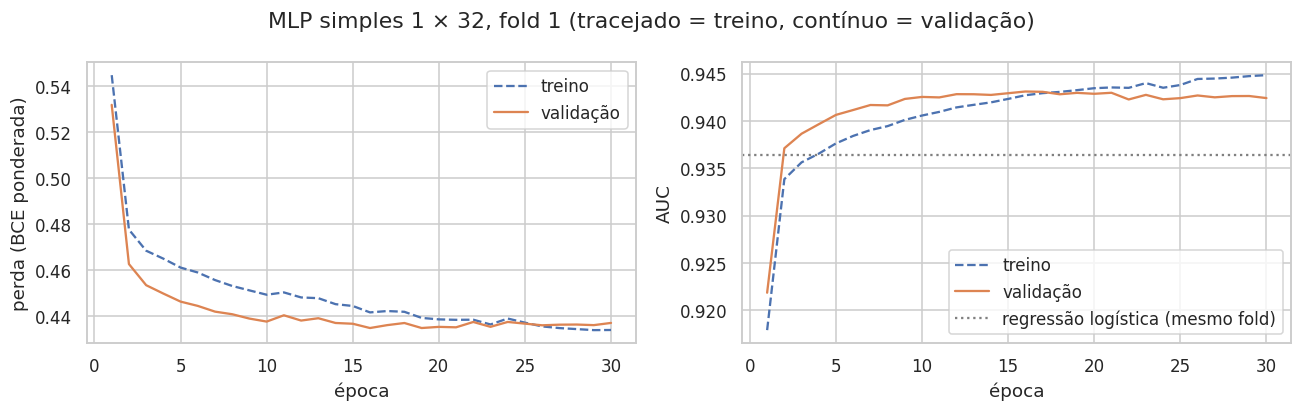

In [15]:
auc_lr_f1 = REF_FOLDS["Regressão logística"].loc[1, "AUC val"]   # regressão logística no fold 1
print("MLP simples 1 × 32 — fold 1, época a época:")
_, hist_base, _ = treinar(FOLDS[0]["Xa"], FOLDS[0]["ya"], FOLDS[0]["Xb"], FOLDS[0]["yb"],
                          hidden=(32,), lr=1e-3, dropout=0.0, verbose=True)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ep = np.arange(1, EPOCHS + 1)
for ax, k, nome in zip(axes, ["loss", "auc"], ["perda (BCE ponderada)", "AUC"]):
    ax.plot(ep, hist_base[f"train_{k}"], "--", label="treino"); ax.plot(ep, hist_base[f"val_{k}"], "-", label="validação")
    ax.set_xlabel("época"); ax.set_ylabel(nome)
axes[1].axhline(auc_lr_f1, color="gray", ls=":", label="regressão logística (mesmo fold)")
axes[0].legend(); axes[1].legend()
fig.suptitle("MLP simples 1 × 32, fold 1 (tracejado = treino, contínuo = validação)")
plt.tight_layout(); salvar(fig, "04_mlp_simples_curvas"); plt.show()

In [16]:
# Resumo das referências, gerado a partir das saídas acima (nenhum número digitado à mão)
ing = ref.loc["Ingênuo (sempre conectado)"]
lr_ = ref.loc["Regressão logística"]
rf_ = ref.loc["Random Forest"]
cel_ = ref.loc["Só tem_celular"]
lr5_ = ref.loc["Regressão logística (5 variáveis)"]
v = np.array(hist_base["val_auc"])
passa = np.flatnonzero(v > auc_lr_f1)
txt_passa = (f"passa da logística (no mesmo fold) na época **{passa[0] + 1}**" if len(passa)
             else "**não passa** da logística no mesmo fold em nenhuma época")
display(Markdown(f"""
**Resumo das referências (validação cruzada, {K_FOLDS} folds no treino)**

* **Ingênuo:** acurácia de **{pct(ing['acurácia val'])}**, com recall de **{pct(ing['recall val'])}**.
* **Só `tem_celular`:** AUC de validação **{br(cel_['AUC val'])}**, usando apenas uma pergunta.
* **Regressão logística com 5 variáveis:** AUC de validação **{br(lr5_['AUC val'])} ± {br(lr5_['DP AUC val'])}**.
* **Regressão logística (todas as variáveis):** AUC de validação **{br(lr_['AUC val'])} ± {br(lr_['DP AUC val'])}**, recall {pct(lr_['recall val'])},
  precisão {pct(lr_['precisão val'])}; gap treino − validação de {br(lr_['gap AUC'], 4)}.
* **Random Forest:** AUC de validação **{br(rf_['AUC val'])} ± {br(rf_['DP AUC val'])}**, recall {pct(rf_['recall val'])},
  precisão {pct(rf_['precisão val'])}; gap treino − validação de **{br(rf_['gap AUC'], 4)}**.
* **MLP simples (1 × 32), fold 1:** {txt_passa}. AUC de validação na última época: {br(v[-1])}; maior valor:
  {br(v.max())} (época {int(v.argmax()) + 1}). Regressão logística no mesmo fold: {br(auc_lr_f1)}.
"""))


**Resumo das referências (validação cruzada, 5 folds no treino)**

* **Ingênuo:** acurácia de **72,4%**, com recall de **0,0%**.
* **Só `tem_celular`:** AUC de validação **0,813**, usando apenas uma pergunta.
* **Regressão logística com 5 variáveis:** AUC de validação **0,924 ± 0,002**.
* **Regressão logística (todas as variáveis):** AUC de validação **0,934 ± 0,002**, recall 83,1%,
  precisão 75,1%; gap treino − validação de 0,0005.
* **Random Forest:** AUC de validação **0,934 ± 0,003**, recall 84,3%,
  precisão 74,3%; gap treino − validação de **0,0130**.
* **MLP simples (1 × 32), fold 1:** passa da logística (no mesmo fold) na época **2**. AUC de validação na última época: 0,942; maior valor:
  0,943 (época 16). Regressão logística no mesmo fold: 0,936.


**Como ler as referências**

* O **modelo ingênuo** mostra por que acurácia sozinha engana: ele acerta a maioria dos casos sem encontrar nenhum idoso
  desconectado. Por isso o critério de escolha é a AUC.
* **Uma pergunta só já resolve boa parte do problema:** saber se a pessoa tem celular próprio chega a uma AUC de 0,813.
  Uma logística com 5 variáveis (celular, outros moradores conectados, outros moradores com celular, idade e anos de
  estudo) chega a 0,924, perto dos 0,934 da logística com todas as variáveis. É contra esse patamar que a MLP precisa
  ser lida.
* A **regressão logística** já é forte e praticamente não sobreajusta: treino e validação ficam quase iguais. É a
  referência linear que a MLP precisa superar.
* O **Random Forest** empata com a logística na validação, mas tem um gap maior: com folhas de no mínimo 20 pessoas e sem
  limite de profundidade, as árvores se ajustam mais ao treino.
* A **MLP simples**, comparada no mesmo fold, passa da logística logo nas primeiras épocas e depois estabiliza.

## 5. Busca de hiperparâmetros

**Desenho experimental.** Grade completa de **3 hiperparâmetros**, totalizando **3 × 2 × 2 = 12 combinações**, cada uma
avaliada com **validação cruzada de K folds dentro do treino** (o teste não participa).

| Hiperparâmetro | Valores | Por que estes valores |
|---|---|---|
| Arquitetura (camadas ocultas × neurônios) | 1 × 32 · 2 camadas (64, 32) · 3 camadas (128, 64, 32) | De uma rede rasa a uma mais profunda; largura e profundidade mudam a capacidade de sobreajustar |
| Learning rate (Adam) | 0,01 · 0,001 | 0,001 é o padrão do Adam; 0,01 testa passos maiores |
| Dropout | 0 · 0,3 | Sem regularização × regularização moderada |

*Mantidos fixos* para isolar o efeito dos três: Adam, batch 256, até 30 épocas, mesma semente por fold.

**Como cada aspecto é medido e como a combinação é escolhida**

| Aspecto | Como |
|---|---|
| Desempenho | AUC média de validação **na melhor época de cada combinação**. A AUC da última época também é mostrada |
| Estabilidade | desvio-padrão (DP) da AUC entre os folds e erro-padrão da média (EP = DP / √5), na melhor época |
| Overfitting | gap = AUC treino − AUC validação; perda de validação em "U" ao longo das épocas |
| Escolha | **regra de 1 erro-padrão**: entre as combinações com AUC a até 1 EP da melhor, fica a **mais simples** (menos parâmetros). Desempate, nesta ordem: maior AUC arredondada a 3 casas, maior dropout, menor learning rate |
| Épocas do modelo final | a melhor época (maior AUC média de validação) da combinação escolhida |

*Por que medir na melhor época:* comparar todas as combinações na época 30 pune as que aprendem rápido e depois
sobreajustam. Medir cada uma no seu melhor momento compara o que cada configuração consegue de fato. Escolher a melhor
entre 30 épocas pela validação é levemente otimista, mas o efeito é o mesmo para todas.

*Por que a regra de 1 erro-padrão:* a AUC média de validação é uma estimativa feita com 5 folds, e o erro-padrão (EP)
mede a incerteza **dessa média**. O desvio-padrão (DP) mede outra coisa: quanto **cada fold** varia. Como a média de 5
folds é mais precisa que um fold isolado, o EP é menor que o DP (EP = DP / √5), e é ele que diz se a diferença entre
duas médias pode ser só ruído. Entre as combinações que ficam a até 1 EP da melhor, a mais simples é a escolha mais
segura, porque tem menos capacidade de decorar o treino.

*Por que o desempate é arredondado:* quando duas redes do mesmo tamanho diferem só na 4ª casa decimal, a ordem entre elas
pode mudar de GPU para CPU. Arredondar a 3 casas e desempatar por regras fixas (mais regularização) faz a escolha sair
igual nos dois ambientes.

In [17]:
HIDDENS = [(32,), (64, 32), (128, 64, 32)]
LRS = [1e-2, 1e-3]
DROPOUTS = [0.0, 0.3]
GRADE = [dict(hidden=h, lr=lr, dropout=d) for h in HIDDENS for lr in LRS for d in DROPOUTS]
print(f"{len(GRADE)} combinações × {K_FOLDS} folds = {len(GRADE) * K_FOLDS} treinos")

def nome_cfg(c):
    return f"{'×'.join(map(str, c['hidden']))} | lr={c['lr']} | drop={c['dropout']}"

RESULTADOS = []
for cfg in GRADE:
    t0 = time.time()
    hists = []
    for k, f in enumerate(FOLDS):
        model, hist, _ = treinar(f["Xa"], f["ya"], f["Xb"], f["yb"], **cfg, seed=SEED + k)
        hists.append(hist)
    H = {chave: np.array([h[chave] for h in hists]) for chave in hists[0]}   # matrizes folds × épocas
    media = {chave: m.mean(axis=0) for chave, m in H.items()}
    e = int(np.argmax(media["val_auc"]))                                    # melhor época (índice)
    r = dict(nome=nome_cfg(cfg), arquitetura="×".join(map(str, cfg["hidden"])), **cfg, params=n_params(model),
             auc_val_ult=media["val_auc"][-1], auc_treino_ult=media["train_auc"][-1],
             gap_ult=media["train_auc"][-1] - media["val_auc"][-1],
             epoca_auc=e + 1, auc_val=media["val_auc"][e], auc_val_dp=H["val_auc"][:, e].std(),
             auc_val_ep=H["val_auc"][:, e].std(ddof=1) / np.sqrt(len(FOLDS)),
             auc_treino=media["train_auc"][e], gap=media["train_auc"][e] - media["val_auc"][e],
             auc_val_folds=H["val_auc"][:, e], epoca_perda=int(np.argmin(media["val_loss"])) + 1,
             hist=media, tempo_s=time.time() - t0)
    RESULTADOS.append(r)
    print(f"{r['nome']:<32s} params={r['params']:>6,d} | AUC val época {EPOCHS}: {r['auc_val_ult']:.4f} | "
          f"melhor época {r['epoca_auc']:2d}: {r['auc_val']:.4f} (DP {r['auc_val_dp']:.4f}, EP {r['auc_val_ep']:.4f}), gap {r['gap']:+.4f} | "
          f"menor perda val: época {r['epoca_perda']:2d} | {r['tempo_s']:.0f}s")

12 combinações × 5 folds = 60 treinos
32 | lr=0.01 | drop=0.0          params= 1,889 | AUC val época 30: 0.9390 | melhor época  8: 0.9403 (DP 0.0016, EP 0.0008), gap +0.0044 | menor perda val: época  9 | 63s
32 | lr=0.01 | drop=0.3          params= 1,889 | AUC val época 30: 0.9400 | melhor época 30: 0.9400 (DP 0.0017, EP 0.0009), gap +0.0048 | menor perda val: época 20 | 67s
32 | lr=0.001 | drop=0.0         params= 1,889 | AUC val época 30: 0.9401 | melhor época 21: 0.9401 (DP 0.0020, EP 0.0010), gap +0.0036 | menor perda val: época 25 | 63s
32 | lr=0.001 | drop=0.3         params= 1,889 | AUC val época 30: 0.9403 | melhor época 30: 0.9403 (DP 0.0018, EP 0.0009), gap +0.0032 | menor perda val: época 28 | 67s
64×32 | lr=0.01 | drop=0.0       params= 5,825 | AUC val época 30: 0.9328 | melhor época  7: 0.9396 (DP 0.0014, EP 0.0007), gap +0.0067 | menor perda val: época  9 | 71s
64×32 | lr=0.01 | drop=0.3       params= 5,825 | AUC val época 30: 0.9393 | melhor época  8: 0.9401 (DP 0.0017, 

Maior AUC média de validação: 64×32 | lr=0.001 | drop=0.3 (0.9408; DP 0.0018, EP 0.0009)
Limite da regra de 1 EP: 0.9398 → 9 combinação(ões) empatada(s) com a melhor
Escolhida (a mais simples entre as empatadas): 32 | lr=0.001 | drop=0.3 | 1,889 parâmetros | 30 épocas


,nº parâmetros,AUC val (época 30),gap (época 30),melhor época,AUC val (melhor época),DP entre folds,EP da média,AUC treino (melhor época),gap (melhor época),época de menor perda val,empata com a melhor (1 EP),tempo (s)
combinação,,,,,,,,,,,,
64×32 | lr=0.001 | drop=0.3,5825,0.9406,0.0086,20,0.9408,0.0018,0.0009,0.9473,0.0065,19,True,79.8607
128×64×32 | lr=0.001 | drop=0.0,17793,0.9353,0.0232,8,0.9407,0.0018,0.0009,0.9468,0.0061,9,True,80.6614
128×64×32 | lr=0.001 | drop=0.3,17793,0.9390,0.0157,11,0.9406,0.0018,0.0009,0.9475,0.0069,13,True,91.0618
32 | lr=0.001 | drop=0.3,1889,0.9403,0.0032,30,0.9403,0.0018,0.0009,0.9435,0.0032,28,True,66.6705
32 | lr=0.01 | drop=0.0,1889,0.9390,0.0094,8,0.9403,0.0016,0.0008,0.9447,0.0044,9,True,63.1308
64×32 | lr=0.001 | drop=0.0,5825,0.9393,0.0103,16,0.9403,0.0019,0.0010,0.9466,0.0064,19,True,71.4937
32 | lr=0.001 | drop=0.0,1889,0.9401,0.0048,21,0.9401,0.0020,0.0010,0.9437,0.0036,25,True,63.4276
64×32 | lr=0.01 | drop=0.3,5825,0.9393,0.0104,8,0.9401,0.0017,0.0008,0.9448,0.0048,9,True,79.6225
32 | lr=0.01 | drop=0.3,1889,0.9400,0.0048,30,0.9400,0.0017,0.0009,0.9448,0.0048,20,True,66.8067


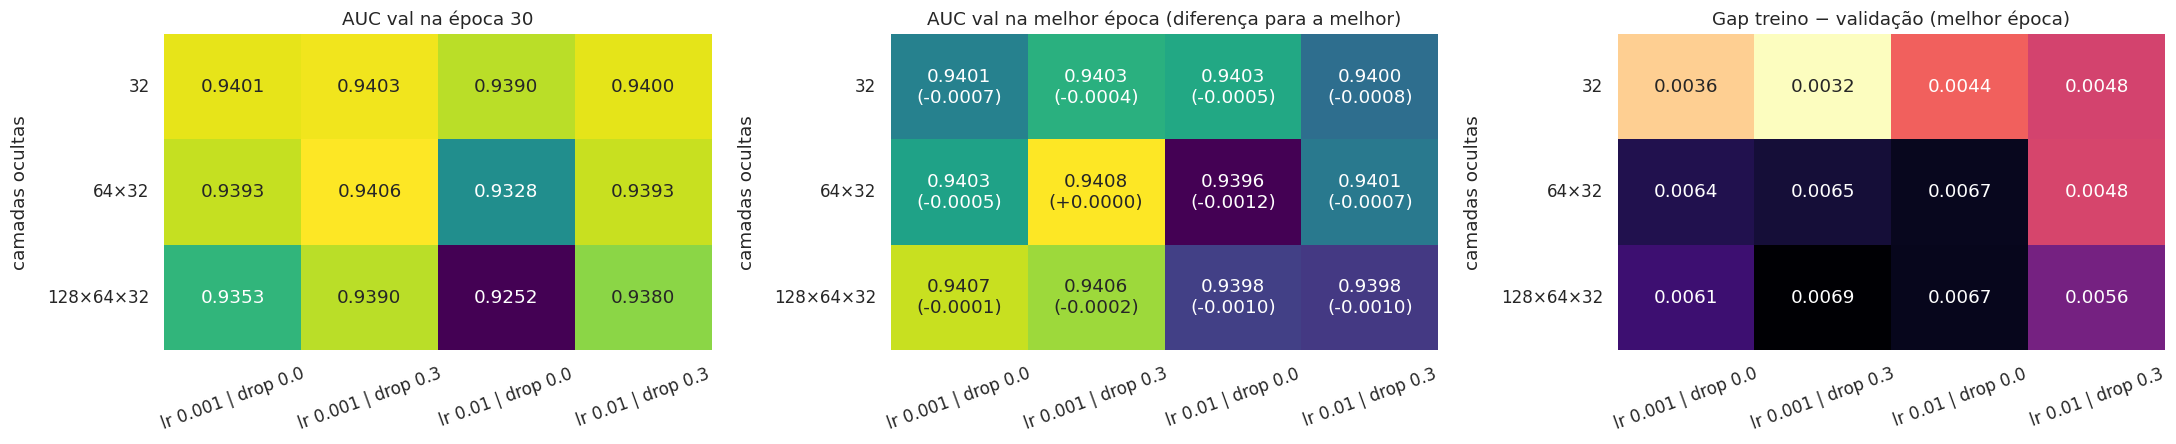

In [18]:
df_grade = pd.DataFrame([{k: v for k, v in r.items() if k not in ("hist", "auc_val_folds")} for r in RESULTADOS])

# Regra de 1 erro-padrão (EP = DP / √K, da combinação de maior AUC)
lider = df_grade.loc[df_grade["auc_val"].idxmax()]
limite = lider["auc_val"] - lider["auc_val_ep"]
df_grade["empata com a melhor (1 EP)"] = df_grade["auc_val"] >= limite
# Desempate estável entre GPU e CPU: menos parâmetros; maior AUC arredondada a 3 casas; mais dropout; menor learning rate
candidatas = (df_grade[df_grade["empata com a melhor (1 EP)"]]
              .assign(auc_3=lambda t: t["auc_val"].round(3))
              .sort_values(["params", "auc_3", "dropout", "lr"], ascending=[True, False, False, True]))
ESCOLHIDA = next(r for r in RESULTADOS if r["nome"] == candidatas.iloc[0]["nome"])
print(f"Maior AUC média de validação: {lider['nome']} ({lider['auc_val']:.4f}; DP {lider['auc_val_dp']:.4f}, "
      f"EP {lider['auc_val_ep']:.4f})")
print(f"Limite da regra de 1 EP: {limite:.4f} → {len(candidatas)} combinação(ões) empatada(s) com a melhor")
print(f"Escolhida (a mais simples entre as empatadas): {ESCOLHIDA['nome']} | {ESCOLHIDA['params']:,} parâmetros | "
      f"{ESCOLHIDA['epoca_auc']} épocas")

tab = df_grade.sort_values("auc_val", ascending=False)[
    ["nome", "params", "auc_val_ult", "gap_ult", "epoca_auc", "auc_val", "auc_val_dp", "auc_val_ep", "auc_treino", "gap",
     "epoca_perda", "empata com a melhor (1 EP)", "tempo_s"]]
display(tab.rename(columns={
    "nome": "combinação", "params": "nº parâmetros", "auc_val_ult": f"AUC val (época {EPOCHS})",
    "gap_ult": f"gap (época {EPOCHS})", "epoca_auc": "melhor época", "auc_val": "AUC val (melhor época)",
    "auc_val_dp": "DP entre folds", "auc_val_ep": "EP da média", "auc_treino": "AUC treino (melhor época)", "gap": "gap (melhor época)",
    "epoca_perda": "época de menor perda val", "tempo_s": "tempo (s)"}).set_index("combinação"))

df_grade["lr | dropout"] = df_grade.apply(lambda r: f"lr {r['lr']} | drop {r['dropout']}", axis=1)
fig, axes = plt.subplots(1, 3, figsize=(20, 4.2))
for ax, (col, titulo, fmt, cmap) in zip(axes, [("auc_val_ult", f"AUC val na época {EPOCHS}", ".4f", "viridis"),
                                               ("auc_val", "AUC val na melhor época (diferença para a melhor)", ".4f", "viridis"),
                                               ("gap", "Gap treino − validação (melhor época)", ".4f", "magma_r")]):
    piv = df_grade.pivot(index="arquitetura", columns="lr | dropout", values=col).loc[["32", "64×32", "128×64×32"]]
    if col == "auc_val":   # anota a diferença em relação à melhor combinação
        rot = piv.apply(lambda c: [f"{v:.4f}\n({v - piv.values.max():+.4f})" for v in c])
        sns.heatmap(piv, annot=rot.values, fmt="", cmap=cmap, ax=ax, cbar=False)
    else:
        sns.heatmap(piv, annot=True, fmt=fmt, cmap=cmap, ax=ax, cbar=False)
    ax.set_title(titulo); ax.set_ylabel("camadas ocultas", labelpad=12); ax.set_xlabel("")
    ax.tick_params(axis="y", rotation=0); ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); salvar(fig, "05_grade_heatmaps"); plt.show()

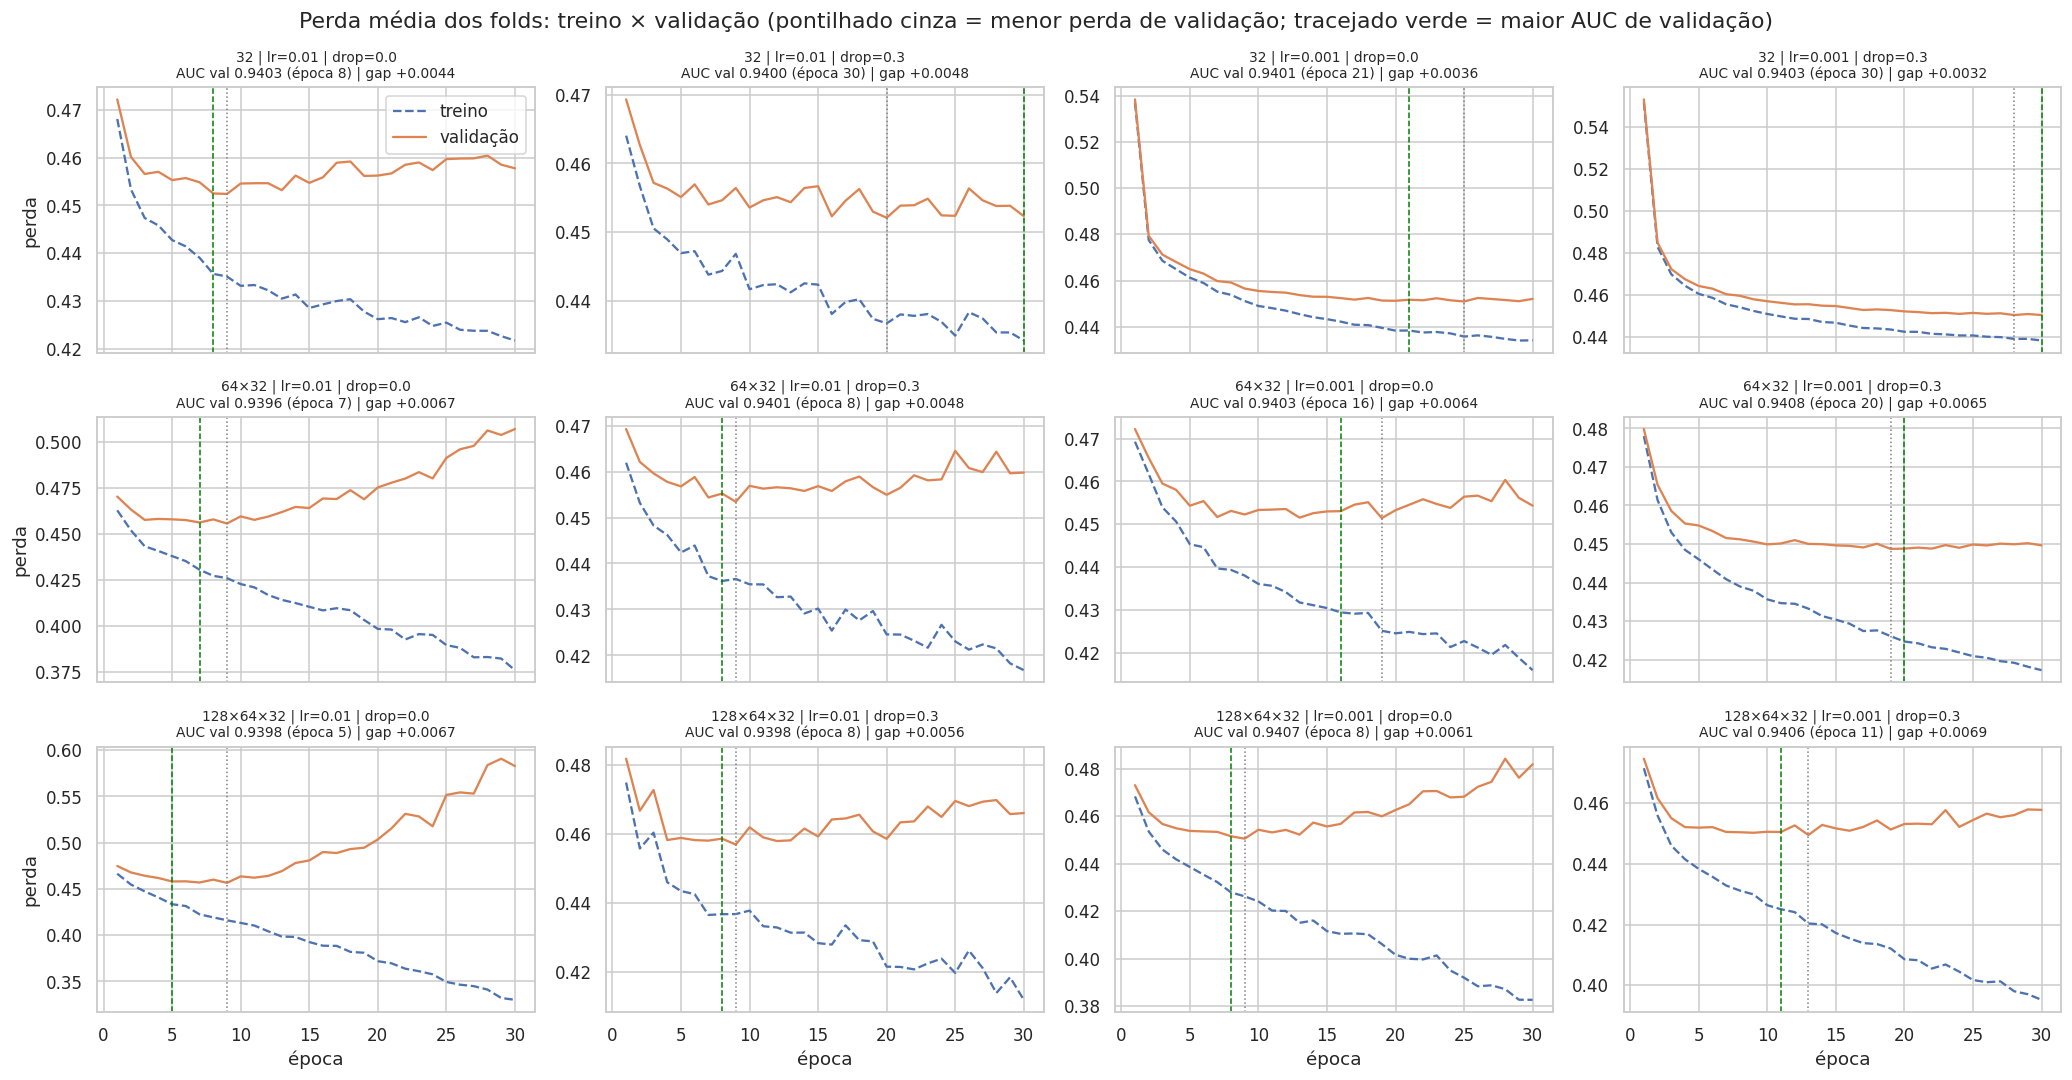

In [19]:
fig, axes = plt.subplots(3, 4, figsize=(19, 10), sharex=True)
for ax, r in zip(axes.ravel(), RESULTADOS):
    ep = np.arange(1, len(r["hist"]["val_loss"]) + 1)
    ax.plot(ep, r["hist"]["train_loss"], "--", label="treino")
    ax.plot(ep, r["hist"]["val_loss"], "-", label="validação")
    ax.axvline(r["epoca_perda"], color="gray", ls=":", lw=1)
    ax.axvline(r["epoca_auc"], color="green", ls="--", lw=1)
    ax.set_title(f"{r['nome']}\nAUC val {r['auc_val']:.4f} (época {r['epoca_auc']}) | gap {r['gap']:+.4f}", fontsize=9)
axes[0, 0].legend(); [a.set_xlabel("época") for a in axes[-1]]; [a.set_ylabel("perda") for a in axes[:, 0]]
fig.suptitle("Perda média dos folds: treino × validação "
             "(pontilhado cinza = menor perda de validação; tracejado verde = maior AUC de validação)")
plt.tight_layout(); salvar(fig, "06_grade_curvas"); plt.show()

### 5.1 A melhor época está no limite da grade?

Se a melhor época da combinação escolhida for a última (época 30), a curva de validação ainda pode estar subindo. Nesse
caso, a mesma combinação é treinada de novo na validação cruzada, com os mesmos folds e as mesmas sementes, por até 60
épocas, e o número de épocas do modelo final passa a ser a melhor época dessa curva estendida.

In [20]:
EPOCHS_EXT = EPOCHS + 3 if QUICK else 60
EXTENSAO = None
if ESCOLHIDA["epoca_auc"] == EPOCHS:
    cfg = dict(hidden=ESCOLHIDA["hidden"], lr=ESCOLHIDA["lr"], dropout=ESCOLHIDA["dropout"])
    t0 = time.time()
    hists = [treinar(f["Xa"], f["ya"], f["Xb"], f["yb"], **cfg, epochs=EPOCHS_EXT, seed=SEED + k)[1]
             for k, f in enumerate(FOLDS)]
    H = {chave: np.array([h[chave] for h in hists]) for chave in hists[0]}
    media = {chave: m.mean(axis=0) for chave, m in H.items()}
    e = int(np.argmax(media["val_auc"]))
    EXTENSAO = dict(epoca_antes=ESCOLHIDA["epoca_auc"], auc_antes=ESCOLHIDA["auc_val"],
                    epoca_depois=e + 1, auc_depois=media["val_auc"][e], max_epocas=EPOCHS_EXT)
    ESCOLHIDA.update(epoca_auc=e + 1, auc_val=media["val_auc"][e], auc_val_dp=H["val_auc"][:, e].std(),
                     auc_val_ep=H["val_auc"][:, e].std(ddof=1) / np.sqrt(len(FOLDS)),
                     auc_treino=media["train_auc"][e], gap=media["train_auc"][e] - media["val_auc"][e],
                     auc_val_folds=H["val_auc"][:, e], epoca_perda=int(np.argmin(media["val_loss"])) + 1, hist=media)
    print(f"Curva estendida até {EPOCHS_EXT} épocas em {time.time() - t0:.0f}s: melhor época "
          f"{EXTENSAO['epoca_antes']} → {EXTENSAO['epoca_depois']} | AUC val {EXTENSAO['auc_antes']:.4f} → "
          f"{EXTENSAO['auc_depois']:.4f}")
else:
    print(f"A melhor época da escolhida ({ESCOLHIDA['epoca_auc']}) está antes do limite: não é preciso estender.")

Curva estendida até 60 épocas em 134s: melhor época 30 → 58 | AUC val 0.9403 → 0.9406


In [21]:
# Resumo da busca, gerado a partir das saídas acima (nenhum número digitado à mão)
dg = df_grade.set_index("nome")
emp = dg[dg["empata com a melhor (1 EP)"]].sort_values("auc_val", ascending=False)
dg["ganho"] = dg["auc_val"] - dg["auc_val_ult"]
grandes = dg[dg["ganho"] > 0.005].sort_values("ganho", ascending=False)
pares = []
for h in HIDDENS:
    for lr in LRS:
        sem = dg.loc[nome_cfg(dict(hidden=h, lr=lr, dropout=0.0))]
        com = dg.loc[nome_cfg(dict(hidden=h, lr=lr, dropout=0.3))]
        pares.append(dict(auc_ult=com["auc_val_ult"] > sem["auc_val_ult"], auc_melhor=com["auc_val"] > sem["auc_val"],
                          gap_ult=com["gap_ult"] < sem["gap_ult"], gap_melhor=com["gap"] < sem["gap"]))
pares = pd.DataFrame(pares)
u = dg[dg["epoca_perda"] <= EPOCHS // 2].sort_values("epoca_perda")
arq = [dg.loc[nome_cfg(dict(hidden=h, lr=1e-2, dropout=0.0))] for h in HIDDENS]
dif_lr = ESCOLHIDA["auc_val_folds"] - REF_FOLDS["Regressão logística"]["AUC val"].to_numpy()
dif_rf = ESCOLHIDA["auc_val_folds"] - REF_FOLDS["Random Forest"]["AUC val"].to_numpy()

txt_emp = "; ".join(emp.index)
txt_grandes = "; ".join(f"{n}: {br(r.auc_val_ult, 4)} → {br(r.auc_val, 4)} (época {int(r.epoca_auc)})"
                        for n, r in grandes.iterrows()) or "nenhuma"
txt_u = "; ".join(f"{n} (época {int(r.epoca_perda)})" for n, r in u.iterrows()) or "nenhuma"
txt_arq_tr = " → ".join(br(a["auc_treino_ult"]) for a in arq)
txt_arq_va = " → ".join(br(a["auc_val_ult"]) for a in arq)
txt_arq_best = " → ".join(br(a["auc_val"]) for a in arq)
txt_ultima = (f"na grade, a melhor época era a última ({EXTENSAO['epoca_antes']}); estendendo a curva até "
              f"{EXTENSAO['max_epocas']} épocas, a melhor passou a ser a **{EXTENSAO['epoca_depois']}** (AUC de validação "
              f"{br(EXTENSAO['auc_antes'], 4)} → {br(EXTENSAO['auc_depois'], 4)})."
              if EXTENSAO else f"a melhor época é a {ESCOLHIDA['epoca_auc']}, antes do fim do treino.")
display(Markdown(f"""
**Resumo da busca (gerado a partir das saídas acima)**

* **Maior AUC média de validação:** {lider['nome']}, **{br(lider['auc_val'], 4)}** (época {int(lider['epoca_auc'])};
  DP entre folds {br(lider['auc_val_dp'], 4)}, EP da média {br(lider['auc_val_ep'], 4)}).
* **Empatadas pela regra de 1 EP** (AUC ≥ {br(limite, 4)}): **{len(emp)} de {len(dg)}** combinações ({txt_emp}).
* **Escolhida:** **{ESCOLHIDA['nome']}**, a mais simples entre as empatadas ({br(ESCOLHIDA['params'], 0)} parâmetros; desempate pela regra fixa),
  com AUC de validação {br(ESCOLHIDA['auc_val'], 4)} (EP {br(ESCOLHIDA['auc_val_ep'], 4)}) na época **{ESCOLHIDA['epoca_auc']}**.
* **Época {EPOCHS} × melhor época:** a AUC média de validação vai de {br(dg['auc_val_ult'].min(), 4)}–{br(dg['auc_val_ult'].max(), 4)}
  na época {EPOCHS} para {br(dg['auc_val'].min(), 4)}–{br(dg['auc_val'].max(), 4)} na melhor época de cada combinação.
  Maiores ganhos ao parar na melhor época: {txt_grandes}.
* **Dropout (6 pares com a mesma arquitetura e o mesmo learning rate):** aumentou a AUC de validação em
  **{int(pares['auc_ult'].sum())} de 6** pares na época {EPOCHS} e em **{int(pares['auc_melhor'].sum())} de 6** na melhor
  época; reduziu o gap em {int(pares['gap_ult'].sum())} de 6 na época {EPOCHS} e em {int(pares['gap_melhor'].sum())} de 6
  na melhor época.
* **Arquitetura (lr 0,01, sem dropout), 1 → 2 → 3 camadas:** na época {EPOCHS}, AUC de treino {txt_arq_tr} e de
  validação {txt_arq_va}; na melhor época, validação {txt_arq_best}.
* **Curvas em U** (menor perda de validação na primeira metade do treino): {txt_u}.
* **Épocas da escolhida:** {txt_ultima}
* **MLP escolhida × regressão logística, fold a fold** (mesmos folds): diferença de AUC de
  **{br(dif_lr.mean(), 4)} ± {br(dif_lr.std(), 4)}**; a MLP fica à frente em {int((dif_lr > 0).sum())} de {K_FOLDS} folds.
* **MLP escolhida × Random Forest, fold a fold:** diferença de AUC de **{br(dif_rf.mean(), 4)} ± {br(dif_rf.std(), 4)}**;
  a MLP fica à frente em {int((dif_rf > 0).sum())} de {K_FOLDS} folds.
"""))


**Resumo da busca (gerado a partir das saídas acima)**

* **Maior AUC média de validação:** 64×32 | lr=0.001 | drop=0.3, **0,9408** (época 20;
  DP entre folds 0,0018, EP da média 0,0009).
* **Empatadas pela regra de 1 EP** (AUC ≥ 0,9398): **9 de 12** combinações (64×32 | lr=0.001 | drop=0.3; 128×64×32 | lr=0.001 | drop=0.0; 128×64×32 | lr=0.001 | drop=0.3; 32 | lr=0.001 | drop=0.3; 32 | lr=0.01 | drop=0.0; 64×32 | lr=0.001 | drop=0.0; 32 | lr=0.001 | drop=0.0; 64×32 | lr=0.01 | drop=0.3; 32 | lr=0.01 | drop=0.3).
* **Escolhida:** **32 | lr=0.001 | drop=0.3**, a mais simples entre as empatadas (1.889 parâmetros; desempate pela regra fixa),
  com AUC de validação 0,9406 (EP 0,0008) na época **58**.
* **Época 30 × melhor época:** a AUC média de validação vai de 0,9252–0,9406
  na época 30 para 0,9396–0,9408 na melhor época de cada combinação.
  Maiores ganhos ao parar na melhor época: 128×64×32 | lr=0.01 | drop=0.0: 0,9252 → 0,9398 (época 5); 64×32 | lr=0.01 | drop=0.0: 0,9328 → 0,9396 (época 7); 128×64×32 | lr=0.001 | drop=0.0: 0,9353 → 0,9407 (época 8).
* **Dropout (6 pares com a mesma arquitetura e o mesmo learning rate):** aumentou a AUC de validação em
  **6 de 6** pares na época 30 e em **3 de 6** na melhor
  época; reduziu o gap em 6 de 6 na época 30 e em 3 de 6
  na melhor época.
* **Arquitetura (lr 0,01, sem dropout), 1 → 2 → 3 camadas:** na época 30, AUC de treino 0,948 → 0,959 → 0,969 e de
  validação 0,939 → 0,933 → 0,925; na melhor época, validação 0,940 → 0,940 → 0,940.
* **Curvas em U** (menor perda de validação na primeira metade do treino): 32 | lr=0.01 | drop=0.0 (época 9); 64×32 | lr=0.01 | drop=0.0 (época 9); 64×32 | lr=0.01 | drop=0.3 (época 9); 128×64×32 | lr=0.01 | drop=0.0 (época 9); 128×64×32 | lr=0.01 | drop=0.3 (época 9); 128×64×32 | lr=0.001 | drop=0.0 (época 9); 128×64×32 | lr=0.001 | drop=0.3 (época 13).
* **Épocas da escolhida:** na grade, a melhor época era a última (30); estendendo a curva até 60 épocas, a melhor passou a ser a **58** (AUC de validação 0,9403 → 0,9406).
* **MLP escolhida × regressão logística, fold a fold** (mesmos folds): diferença de AUC de
  **0,0071 ± 0,0010**; a MLP fica à frente em 5 de 5 folds.
* **MLP escolhida × Random Forest, fold a fold:** diferença de AUC de **0,0071 ± 0,0013**;
  a MLP fica à frente em 5 de 5 folds.


**Como ler a busca**

* **As combinações ficam muito próximas.** Quando a diferença entre duas médias é menor que 1 erro-padrão, ela pode ser
  só ruído da divisão em folds. Por isso a escolha não fica com a maior AUC, e sim com a rede mais simples entre as que
  empatam com a melhor (quais são, e qual foi escolhida, está no resumo acima).
* **Parar na hora certa importa mais que a arquitetura.** Na época 30, as redes maiores com learning rate alto e sem
  dropout ficam bem atrás; medidas na sua melhor época, ficam perto das outras.
* **Dropout:** o efeito dele depende de quando o treino para. Comparado na época 30, ele parece ajudar mais do que quando
  cada combinação é comparada na sua melhor época (a contagem está no resumo). Com uma semente por fold, não dá para
  afirmar um efeito do dropout além disso; ele serve sobretudo como proteção quando não se sabe a hora de parar.
* **Épocas da rede escolhida:** na grade, a melhor época dela era a última (30). Estendida até 60 épocas, a melhor
  passou a ser a 58, mas o ganho de AUC (0,9403 → 0,9406) é menor que 1 EP (0,0008): a curva está num platô, e treinar
  mais não muda o resultado.
* **O "U" por época:** aparece sobretudo com learning rate alto e nas redes de 3 camadas. A perda de validação atinge o
  mínimo cedo e depois sobe, enquanto a de treino continua caindo: é o sinal clássico de overfitting, e é por isso que
  o número de épocas do modelo final vem da validação.
* **Contra as referências**, a comparação é fold a fold, nos mesmos folds (resumo acima). A AUC da MLP é medida na sua
  melhor época, o que a favorece levemente.

### 5.2 O que a MLP aproveita a mais que a regressão logística

A MLP pode combinar variáveis (por exemplo, o efeito da idade pode ser diferente para quem tem e para quem não tem
celular), e a regressão logística não, a não ser que essas combinações sejam dadas a ela. Para ver qual combinação
explica a vantagem da rede, a logística é treinada de novo, nos mesmos folds, com produtos de pares de variáveis
(interações). O grupo de interações que mais aproxima a logística da MLP é o que a rede aproveita a mais.

In [22]:
INTERACOES = {
    "celular × perfil": [("tem_celular", v) for v in ["idade", "anos_estudo", "log_renda_pc", "outros_usam_internet",
                                                       "n_moradores"]],
    "conexão da casa × perfil": [("outros_usam_internet", v) for v in ["idade", "anos_estudo", "log_renda_pc",
                                                                       "n_moradores"]],
    "idade × escolaridade e renda": [("idade", "anos_estudo"), ("idade", "log_renda_pc"), ("anos_estudo", "log_renda_pc")],
}
INTERACOES["todas as anteriores"] = sum(INTERACOES.values(), [])

def col(f, parte, nome):
    for prefixo in ("num__", "bin__"):
        if prefixo + nome in f["nomes"]:
            return f[parte][:, f["nomes"].index(prefixo + nome)]
    raise KeyError(nome)

def cv_logistica_interacoes(pares):
    aucs = []
    for f in FOLDS:
        extra_a = np.column_stack([col(f, "Xa_np", a) * col(f, "Xa_np", b) for a, b in pares])
        extra_b = np.column_stack([col(f, "Xb_np", a) * col(f, "Xb_np", b) for a, b in pares])
        m = nova_logistica().fit(np.hstack([f["Xa_np"], extra_a]), f["ya_np"])
        aucs.append(roc_auc_score(f["yb_np"], m.predict_proba(np.hstack([f["Xb_np"], extra_b]))[:, 1]))
    return np.array(aucs)

auc_lr_f = REF_FOLDS["Regressão logística"]["AUC val"].to_numpy()
auc_mlp_f = ESCOLHIDA["auc_val_folds"]
linhas = []
for nome, pares in INTERACOES.items():
    a = cv_logistica_interacoes(pares)
    linhas.append({"interações": nome, "nº de pares": len(pares), "AUC val (média)": a.mean(),
                   "ganho sobre a logística": (a - auc_lr_f).mean(),
                   "% da vantagem da MLP recuperada": ((a - auc_lr_f).mean() / (auc_mlp_f - auc_lr_f).mean() * 100
                                                       if (auc_mlp_f - auc_lr_f).mean() > 0 else np.nan)})
INTER = pd.DataFrame(linhas).set_index("interações")
print(f"Logística sem interações: {auc_lr_f.mean():.4f} | MLP escolhida: {auc_mlp_f.mean():.4f}")
display(INTER)

Logística sem interações: 0.9335 | MLP escolhida: 0.9406


,nº de pares,AUC val (média),ganho sobre a logística,% da vantagem da MLP recuperada
interações,,,,
celular × perfil,5,0.9340,0.0005,6.5119
conexão da casa × perfil,4,0.9347,0.0011,15.9288
idade × escolaridade e renda,3,0.9335,-0.0000,-0.4063
todas as anteriores,12,0.9352,0.0017,23.7141


**Como ler as interações**

* Com **todas** as interações testadas, a logística vai de 0,9335 para 0,9352 e recupera só **24%** da distância até a MLP
  (0,9406). O grupo que mais ajuda é **conexão da casa × perfil** (16% da vantagem): o efeito de morar com alguém
  conectado muda com a idade, a escolaridade e a renda da pessoa. Celular × perfil recupera 7%, e idade × escolaridade e
  renda, nada.
* Ou seja, nenhum par de variáveis explica sozinho a vantagem da rede. Ela vem de combinações que a MLP aprende sem que
  sejam escritas à mão, e a mais visível é entre a conexão da casa e o perfil do idoso. Como a vantagem total é pequena
  (cerca de 0,007 de AUC), a logística continua sendo uma alternativa razoável e mais simples de explicar.


## 6. Resultados: modelo final, treino × teste

**Escolha:** a combinação indicada pela regra de 1 erro-padrão (seção 5), treinada pelo número de épocas da sua melhor época na
validação cruzada.

O modelo final é treinado com **todo o conjunto de treino**, **sem olhar o teste** em nenhum momento, e avaliado **uma
única vez** no teste. A regressão logística e o Random Forest são treinados nos mesmos dados, para comparação.

**Peso amostral:** o treino é feito sem peso, porque o objetivo é aprender a relação entre perfil e desconexão em cada
pessoa da amostra. Para falar da população brasileira, as métricas do teste também são calculadas com o peso `V1028`
(linhas "ponderado").

In [23]:
EPOCAS_FINAL = ESCOLHIDA["epoca_auc"]
print(f"Modelo final: {ESCOLHIDA['nome']} | {EPOCAS_FINAL} épocas (melhor época na validação cruzada)")

pre_final = novo_preprocessador().fit(Xtr_df)
Xtr_np, Xte_np = pre_final.transform(Xtr_df), pre_final.transform(Xte_df)
Xtr_t, Xte_t = para_tensor(Xtr_np), para_tensor(Xte_np)
ytr_t, yte_t = para_tensor(y_tr).view(-1, 1), para_tensor(y_te).view(-1, 1)
w_te = df.iloc[idx_teste][W].to_numpy()

# o teste não entra no treino: nem como validação, nem para escolher épocas
modelo, _, pw_final = treinar(Xtr_t, ytr_t, hidden=ESCOLHIDA["hidden"], lr=ESCOLHIDA["lr"],
                              dropout=ESCOLHIDA["dropout"], epochs=EPOCAS_FINAL)
_, _, p_tr = avaliar(modelo, Xtr_t, ytr_t, pw_final)
_, _, p_te = avaliar(modelo, Xte_t, yte_t, pw_final)
logreg = nova_logistica().fit(Xtr_np, y_tr)
rf = nova_rf().fit(Xtr_np, y_tr)
P = {"MLP": (p_tr, p_te),
     "Regressão logística": (logreg.predict_proba(Xtr_np)[:, 1], logreg.predict_proba(Xte_np)[:, 1]),
     "Random Forest": (rf.predict_proba(Xtr_np)[:, 1], rf.predict_proba(Xte_np)[:, 1])}

linhas = {}
for nome, (ptr, pte) in P.items():
    linhas[f"{nome} · treino"] = metricas(y_tr, ptr)
    linhas[f"{nome} · teste"] = metricas(y_te, pte)
    linhas[f"{nome} · teste (ponderado)"] = metricas(y_te, pte, w=w_te)
final = pd.DataFrame(linhas).T
for nome in P:
    final.loc[f"{nome} · teste", "gap AUC"] = final.loc[f"{nome} · treino", "AUC"] - final.loc[f"{nome} · teste", "AUC"]
print(f"Parâmetros treináveis da MLP final: {n_params(modelo):,}")
display(final)

Modelo final: 32 | lr=0.001 | drop=0.3 | 58 épocas (melhor época na validação cruzada)
Parâmetros treináveis da MLP final: 1,889


,AUC,PR-AUC,acurácia,acurácia balanceada,precisão,recall,F1,gap AUC
MLP · treino,0.9448,0.8861,0.8886,0.8769,0.7697,0.8508,0.8082,NaN
MLP · teste,0.9434,0.8870,0.8883,0.8756,0.7763,0.8465,0.8099,0.0014
MLP · teste (ponderado),0.9420,0.8729,0.8902,0.8706,0.7634,0.8303,0.7954,NaN
Regressão logística · treino,0.9340,0.8663,0.8780,0.8638,0.7521,0.8320,0.7900,NaN
Regressão logística · teste,0.9353,0.8722,0.8799,0.8662,0.7612,0.8347,0.7963,-0.0013
Regressão logística · teste (ponderado),0.9350,0.8586,0.8834,0.8646,0.7473,0.8259,0.7846,NaN
Random Forest · treino,0.9470,0.8848,0.8836,0.8746,0.7555,0.8545,0.8020,NaN
Random Forest · teste,0.9380,0.8711,0.8813,0.8728,0.7559,0.8533,0.8017,0.0090
Random Forest · teste (ponderado),0.9374,0.8582,0.8888,0.8717,0.7567,0.8364,0.7945,NaN


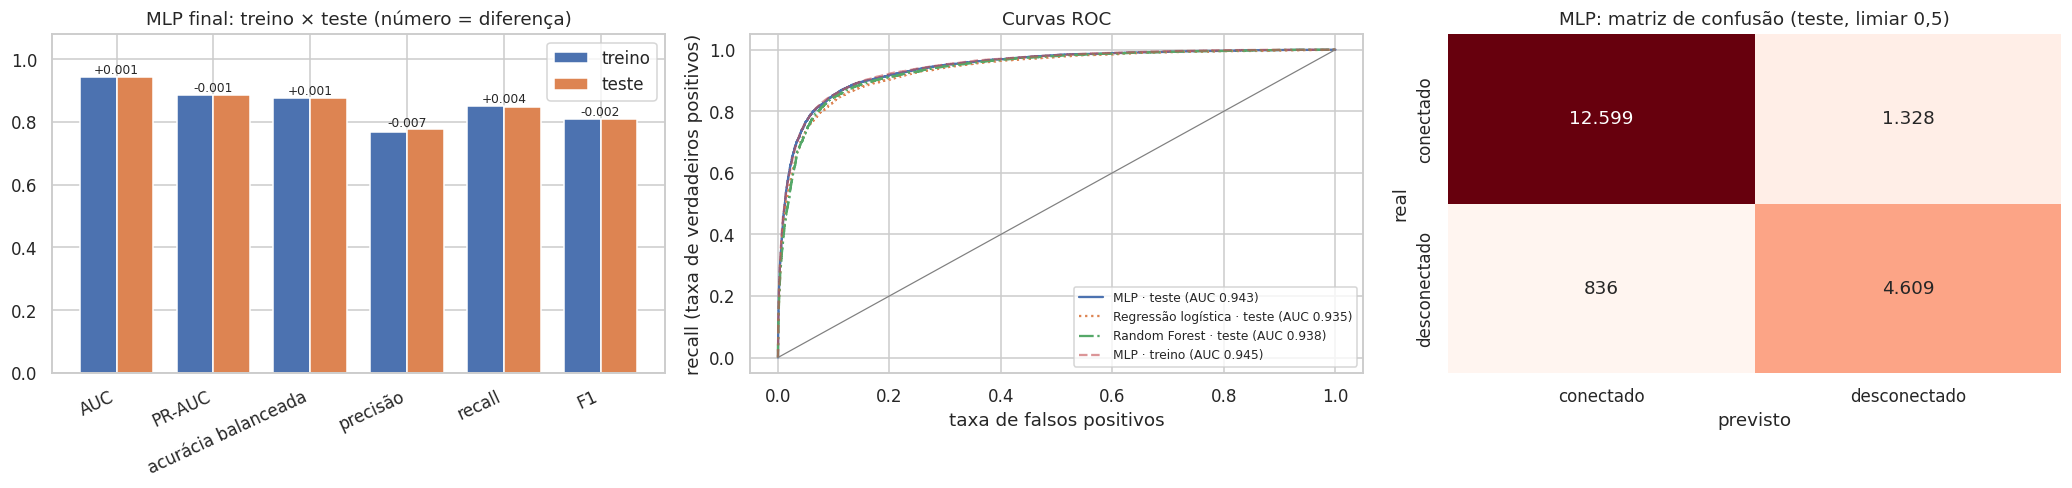

              precision    recall  f1-score   support

   conectado     0.9378    0.9046    0.9209     13927
desconectado     0.7763    0.8465    0.8099      5445

    accuracy                         0.8883     19372
   macro avg     0.8570    0.8756    0.8654     19372
weighted avg     0.8924    0.8883    0.8897     19372



In [24]:
fig, axes = plt.subplots(1, 3, figsize=(19, 4.6))
# (a) métricas treino × teste da MLP
cols = ["AUC", "PR-AUC", "acurácia balanceada", "precisão", "recall", "F1"]
m = final.loc[["MLP · treino", "MLP · teste"], cols]
xs = np.arange(len(cols)); w = .38
axes[0].bar(xs - w / 2, m.loc["MLP · treino"], w, label="treino")
axes[0].bar(xs + w / 2, m.loc["MLP · teste"], w, label="teste")
for i, (a, b) in enumerate(zip(m.loc["MLP · treino"], m.loc["MLP · teste"])):
    axes[0].text(i, max(a, b) + .01, f"{a - b:+.3f}", ha="center", fontsize=8)
axes[0].set_xticks(xs); axes[0].set_xticklabels(cols, rotation=25, ha="right"); axes[0].set_ylim(0, 1.08)
axes[0].set_title("MLP final: treino × teste (número = diferença)"); axes[0].legend()
# (b) curvas ROC
for (nome, (ptr, pte)), est in zip(P.items(), ["-", ":", "-."]):
    fpr, tpr, _ = roc_curve(y_te, pte)
    axes[1].plot(fpr, tpr, est, label=f"{nome} · teste (AUC {roc_auc_score(y_te, pte):.3f})")
fpr, tpr, _ = roc_curve(y_tr, p_tr)
axes[1].plot(fpr, tpr, "--", alpha=.6, label=f"MLP · treino (AUC {roc_auc_score(y_tr, p_tr):.3f})")
axes[1].plot([0, 1], [0, 1], color="gray", lw=.8)
axes[1].set_xlabel("taxa de falsos positivos"); axes[1].set_ylabel("recall (taxa de verdadeiros positivos)")
axes[1].set_title("Curvas ROC"); axes[1].legend(fontsize=8)
# (c) matriz de confusão no teste
cm = confusion_matrix(y_te, (p_te >= .5).astype(int))
sns.heatmap(cm, annot=np.vectorize(lambda v: br(v, 0))(cm), fmt="", cmap="Reds", cbar=False, ax=axes[2],
            xticklabels=["conectado", "desconectado"], yticklabels=["conectado", "desconectado"])
axes[2].set_xlabel("previsto"); axes[2].set_ylabel("real"); axes[2].set_title("MLP: matriz de confusão (teste, limiar 0,5)")
plt.tight_layout(); salvar(fig, "07_final_treino_teste_roc_confusao"); plt.show()
print(classification_report(y_te, (p_te >= .5).astype(int), target_names=["conectado", "desconectado"], digits=4))

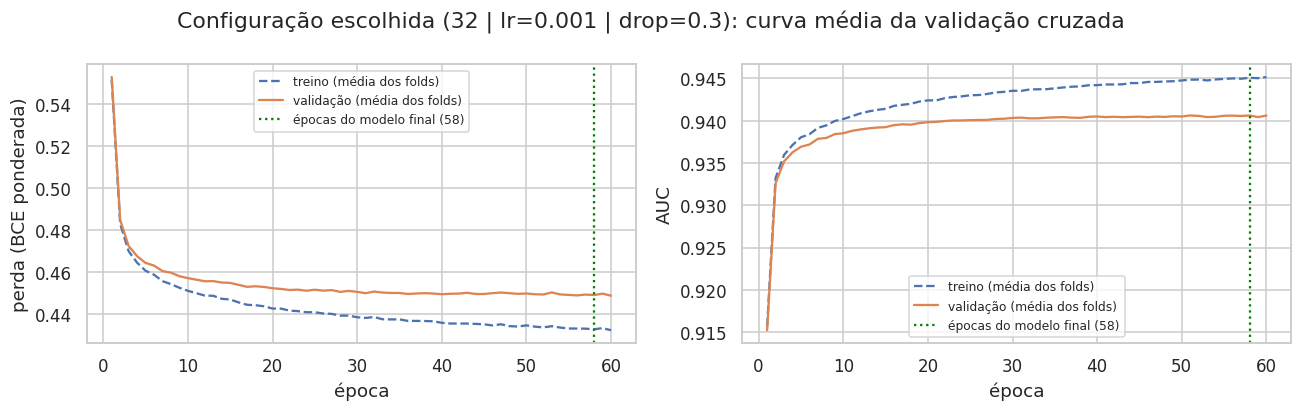

In [25]:
# Curva da configuração escolhida: média da validação cruzada (o teste não é usado aqui)
h = ESCOLHIDA["hist"]
ep = np.arange(1, len(h["val_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, k, nome in zip(axes, ["loss", "auc"], ["perda (BCE ponderada)", "AUC"]):
    ax.plot(ep, h[f"train_{k}"], "--", label="treino (média dos folds)")
    ax.plot(ep, h[f"val_{k}"], "-", label="validação (média dos folds)")
    ax.axvline(EPOCAS_FINAL, color="green", ls=":", label=f"épocas do modelo final ({EPOCAS_FINAL})")
    ax.set_xlabel("época"); ax.set_ylabel(nome); ax.legend(fontsize=8)
fig.suptitle(f"Configuração escolhida ({ESCOLHIDA['nome']}): curva média da validação cruzada")
plt.tight_layout(); salvar(fig, "08_curva_escolhida_cv"); plt.show()

### 6.1 Município de São Paulo

O piloto do Me Conta fica em Pirituba, na capital paulista. A célula abaixo mede o modelo só nos idosos do **município de
São Paulo** que caíram no teste (`Capital = 35`), sem peso e com peso. É uma parte pequena do teste, então os números
servem como indicação para o piloto, não como medida precisa.

In [26]:
te_df = df.iloc[idx_teste]
sp = (te_df["Capital"] == "35").to_numpy()
if sp.sum() and 0 < y_te[sp].sum() < sp.sum():
    sp_tab = pd.DataFrame({"sem peso": metricas(y_te[sp], p_te[sp]),
                           "ponderado": metricas(y_te[sp], p_te[sp], w=w_te[sp])}).T
    print(f"Município de São Paulo no teste: {int(sp.sum()):,} idosos, {int(y_te[sp].sum()):,} desconectados")
    display(sp_tab)
else:
    sp_tab = None
    print("Não há idosos suficientes do município de São Paulo no teste para calcular as métricas.")

Município de São Paulo no teste: 349 idosos, 73 desconectados


,AUC,PR-AUC,acurácia,acurácia balanceada,precisão,recall,F1
sem peso,0.9313,0.8255,0.8883,0.8588,0.7024,0.8082,0.7516
ponderado,0.9333,0.8148,0.8747,0.8510,0.6655,0.8101,0.7307


### 6.2 Incerteza: intervalos por bootstrap

Para saber se a vantagem da MLP sobre a regressão logística no teste é maior que o acaso, e qual a incerteza das
métricas de São Paulo, o teste é reamostrado **por domicílio** (pessoas da mesma casa entram ou saem juntas) 1.000
vezes. O intervalo de 95% vai do percentil 2,5 ao 97,5 das reamostragens.

In [27]:
B = 200 if QUICK else 1000
rng_b = np.random.default_rng(SEED)
g_te = grupos[idx_teste]
_, cod_dom = np.unique(g_te, return_inverse=True)
n_dom = cod_dom.max() + 1
p_lr = P["Regressão logística"][1]

def reamostra():
    # peso de cada pessoa = quantas vezes o domicílio dela foi sorteado
    return np.bincount(rng_b.integers(0, n_dom, n_dom), minlength=n_dom)[cod_dom].astype(float)

boot = {"AUC MLP − AUC logística": [], "SP · AUC": [], "SP · recall ponderado": [], "SP · precisão ponderada": []}
pred_sp = (p_te[sp] >= .5).astype(int)
for _ in range(B):
    r = reamostra()
    boot["AUC MLP − AUC logística"].append(roc_auc_score(y_te, p_te, sample_weight=r)
                                           - roc_auc_score(y_te, p_lr, sample_weight=r))
    rs = r[sp]
    if rs.sum() and 0 < (y_te[sp] * rs).sum() < rs.sum():
        boot["SP · AUC"].append(roc_auc_score(y_te[sp], p_te[sp], sample_weight=rs))
        boot["SP · recall ponderado"].append(recall_score(y_te[sp], pred_sp, sample_weight=rs * w_te[sp], zero_division=0))
        boot["SP · precisão ponderada"].append(precision_score(y_te[sp], pred_sp, sample_weight=rs * w_te[sp],
                                                               zero_division=0))
estim = {"AUC MLP − AUC logística": roc_auc_score(y_te, p_te) - roc_auc_score(y_te, p_lr)}
if sp_tab is not None:
    estim.update({"SP · AUC": sp_tab.loc["sem peso", "AUC"], "SP · recall ponderado": sp_tab.loc["ponderado", "recall"],
                  "SP · precisão ponderada": sp_tab.loc["ponderado", "precisão"]})
IC = pd.DataFrame({k: {"estimativa": estim.get(k, np.nan), "IC 95% inferior": np.percentile(v, 2.5),
                       "IC 95% superior": np.percentile(v, 97.5), "reamostragens válidas": len(v)}
                   for k, v in boot.items() if len(v)}).T
display(IC)

,estimativa,IC 95% inferior,IC 95% superior,reamostragens válidas
AUC MLP − AUC logística,0.0081,0.0068,0.0095,1000.0000
SP · AUC,0.9313,0.8927,0.9654,1000.0000
SP · recall ponderado,0.8101,0.7066,0.8999,1000.0000
SP · precisão ponderada,0.6655,0.5533,0.7723,1000.0000


In [28]:
# Resumo dos resultados no teste, gerado a partir das saídas acima (nenhum número digitado à mão)
mtr, mt, mtw = final.loc["MLP · treino"], final.loc["MLP · teste"], final.loc["MLP · teste (ponderado)"]
lt, ltw = final.loc["Regressão logística · teste"], final.loc["Regressão logística · teste (ponderado)"]
rt, rtw = final.loc["Random Forest · teste"], final.loc["Random Forest · teste (ponderado)"]
tn, fp, fn, tp = confusion_matrix(y_te, (p_te >= .5).astype(int)).ravel()
achados_lr = int((((P["Regressão logística"][1] >= .5).astype(int) == 1) & (y_te == 1)).sum())
dif_achados = int(tp) - achados_lr
txt_achados = f"{br(abs(dif_achados), 0)} desconectados {'a mais' if dif_achados >= 0 else 'a menos'}"
cols = ["acurácia", "acurácia balanceada", "precisão", "recall", "F1"]
dif_max = (mtr[cols] - mt[cols]).abs().max()
gap = mtr["AUC"] - mt["AUC"]
nivel = "muito pouco" if gap < 0.01 else ("moderado" if gap < 0.03 else "relevante")
txt_sp = ("sem idosos suficientes do município no teste" if sp_tab is None else
          f"{int(sp.sum())} idosos no teste; AUC {br(sp_tab.loc['sem peso', 'AUC'])}, recall ponderado "
          f"{pct(sp_tab.loc['ponderado', 'recall'])} e precisão ponderada {pct(sp_tab.loc['ponderado', 'precisão'])}")
ic = IC.loc["AUC MLP − AUC logística"]
txt_ic = (f"diferença de AUC MLP − logística de {br(ic['estimativa'], 4)} "
          f"({br(ic['IC 95% inferior'], 4)} a {br(ic['IC 95% superior'], 4)}); "
          + ("o intervalo não inclui o zero." if ic["IC 95% inferior"] > 0 else "o intervalo inclui o zero.")
          + ("" if "SP · AUC" not in IC.index else
             f" São Paulo: AUC de {br(IC.loc['SP · AUC', 'IC 95% inferior'])} a {br(IC.loc['SP · AUC', 'IC 95% superior'])}, "
             f"recall ponderado de {pct(IC.loc['SP · recall ponderado', 'IC 95% inferior'])} a "
             f"{pct(IC.loc['SP · recall ponderado', 'IC 95% superior'])}, precisão ponderada de "
             f"{pct(IC.loc['SP · precisão ponderada', 'IC 95% inferior'])} a "
             f"{pct(IC.loc['SP · precisão ponderada', 'IC 95% superior'])}."))
display(Markdown(f"""
**Resumo dos resultados no teste (gerado a partir das saídas acima)**

* **Modelo final:** {ESCOLHIDA['nome']}, {EPOCAS_FINAL} épocas, {br(n_params(modelo), 0)} parâmetros.
* **Teste (amostra, sem peso):** AUC **{br(mt['AUC'])}**, PR-AUC {br(mt['PR-AUC'])}, acurácia {pct(mt['acurácia'])},
  acurácia balanceada {br(mt['acurácia balanceada'])}, recall {pct(mt['recall'])}, precisão {pct(mt['precisão'])},
  F1 {br(mt['F1'])}.
* **Teste ponderado pela população (`V1028`):** AUC {br(mtw['AUC'])}, **recall {pct(mtw['recall'])}**, **precisão
  {pct(mtw['precisão'])}**. Em linguagem simples: de cada 10 idosos desconectados no Brasil, o modelo encontra cerca de
  **{br(10 * mtw['recall'], 1)}**; de cada 10 que ele aponta, cerca de **{br(10 * mtw['precisão'], 1)}** estão de fato
  desconectados.
* **Matriz de confusão (amostra de teste):** {br(tp, 0)} de {br(tp + fn, 0)} desconectados encontrados, {br(fn, 0)} não
  encontrados e {br(fp, 0)} alarmes falsos entre {br(tn + fp, 0)} conectados.
* **Contra as referências (teste, sem peso):** regressão logística com AUC {br(lt['AUC'])} e recall {pct(lt['recall'])};
  Random Forest com AUC {br(rt['AUC'])} e recall {pct(rt['recall'])}. Com o limiar de 0,5, a MLP encontra {txt_achados}
  que a logística (precisão {pct(mt['precisão'])} × {pct(lt['precisão'])}). Ponderado: AUC {br(mtw['AUC'])} (MLP),
  {br(ltw['AUC'])} (logística) e {br(rtw['AUC'])} (Random Forest).
* **Overfitting no modelo final: {nivel}.** AUC de treino {br(mtr['AUC'])} × teste {br(mt['AUC'])} (gap de {br(gap, 4)});
  nas demais métricas, a maior diferença entre treino e teste é de {br(dif_max)}.
* **Município de São Paulo:** {txt_sp}.
* **Incerteza (bootstrap por domicílio, IC 95%):** {txt_ic}
"""))


**Resumo dos resultados no teste (gerado a partir das saídas acima)**

* **Modelo final:** 32 | lr=0.001 | drop=0.3, 58 épocas, 1.889 parâmetros.
* **Teste (amostra, sem peso):** AUC **0,943**, PR-AUC 0,887, acurácia 88,8%,
  acurácia balanceada 0,876, recall 84,6%, precisão 77,6%,
  F1 0,810.
* **Teste ponderado pela população (`V1028`):** AUC 0,942, **recall 83,0%**, **precisão
  76,3%**. Em linguagem simples: de cada 10 idosos desconectados no Brasil, o modelo encontra cerca de
  **8,3**; de cada 10 que ele aponta, cerca de **7,6** estão de fato
  desconectados.
* **Matriz de confusão (amostra de teste):** 4.609 de 5.445 desconectados encontrados, 836 não
  encontrados e 1.328 alarmes falsos entre 13.927 conectados.
* **Contra as referências (teste, sem peso):** regressão logística com AUC 0,935 e recall 83,5%;
  Random Forest com AUC 0,938 e recall 85,3%. Com o limiar de 0,5, a MLP encontra 64 desconectados a mais
  que a logística (precisão 77,6% × 76,1%). Ponderado: AUC 0,942 (MLP),
  0,935 (logística) e 0,937 (Random Forest).
* **Overfitting no modelo final: muito pouco.** AUC de treino 0,945 × teste 0,943 (gap de 0,0014);
  nas demais métricas, a maior diferença entre treino e teste é de 0,007.
* **Município de São Paulo:** 349 idosos no teste; AUC 0,931, recall ponderado 81,0% e precisão ponderada 66,6%.
* **Incerteza (bootstrap por domicílio, IC 95%):** diferença de AUC MLP − logística de 0,0081 (0,0068 a 0,0095); o intervalo não inclui o zero. São Paulo: AUC de 0,893 a 0,965, recall ponderado de 70,7% a 90,0%, precisão ponderada de 55,3% a 77,2%.


**Como ler os resultados**

* A **AUC** mede se o modelo **ordena** bem: se os idosos desconectados recebem um risco maior que os conectados. Recall e
  precisão dependem do limiar de 0,5.
* Os números **ponderados** são os que valem para falar da população brasileira; os sem peso descrevem a amostra. Os dois
  ficam próximos.
* **Quase não há overfitting:** treino e teste praticamente coincidem. A configuração e o número de épocas vieram só da
  validação cruzada, e o teste foi usado uma única vez, por isso essa comparação é honesta.
* A MLP fica à frente das duas referências também no teste, mas por pouco. A diferença de AUC para a logística é
  pequena, mas o intervalo de 95% do bootstrap não inclui o zero (resumo acima). Para estes dados, um modelo linear bem
  preparado chega perto de uma rede neural.
* No **município de São Paulo**, a AUC fica perto da geral, e a precisão, um pouco abaixo. Os intervalos do bootstrap
  são largos, porque é uma parte pequena do teste: o resultado serve como indicação para o piloto, não como medida
  precisa.

## 7. O que o modelo aprendeu

Três leituras complementares, todas no conjunto de teste:

1. **Permutação individual:** embaralha uma variável de cada vez e mede quanto a AUC cai. Quando as variáveis são
   correlacionadas, como as do domicílio, embaralhar só uma cria combinações impossíveis (por exemplo, 3 moradores
   conectados numa casa de 1 pessoa), e a queda fica inflada.
2. **Permutação em bloco:** embaralha juntas, com a mesma ordem, as variáveis de um mesmo grupo. As combinações dentro do
   bloco continuam coerentes.
3. **Retirar e retreinar (seção 7.2):** treina o modelo de novo sem a variável, com a mesma configuração e as mesmas
   épocas, e mede o resultado no teste. Mostra o que o modelo **não consegue recuperar** pelas outras variáveis.

**Importância não tem sinal nem indica causa.** Ela diz quanto o modelo depende de uma variável, não se essa variável
aumenta ou diminui o risco, nem se ela provoca a desconexão.

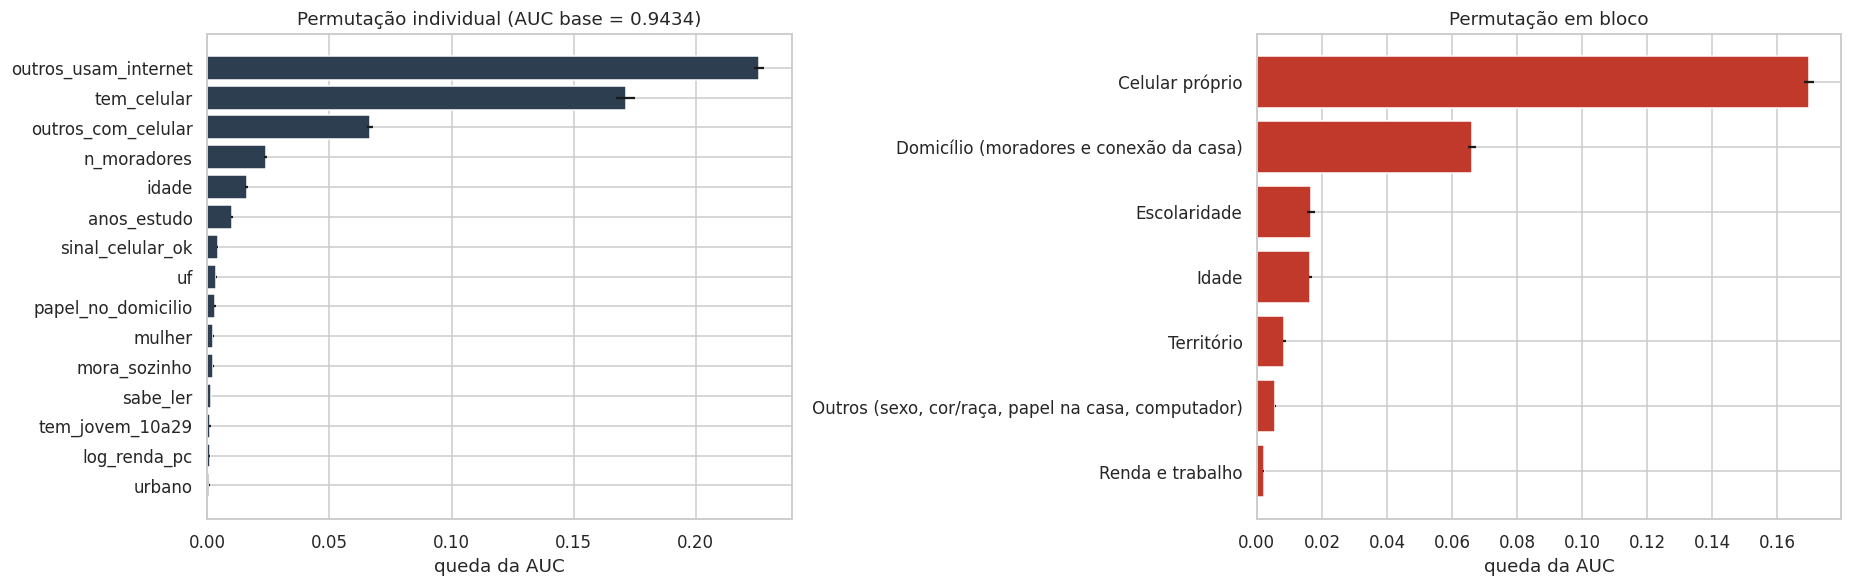

,queda da AUC,DP
variável,,
outros_usam_internet,0.2259,0.0020
tem_celular,0.1713,0.0038
outros_com_celular,0.0667,0.0012
n_moradores,0.0239,0.0006
idade,0.0161,0.0007
anos_estudo,0.0100,0.0005
sinal_celular_ok,0.0043,0.0002
uf,0.0038,0.0002
papel_no_domicilio,0.0032,0.0005


,queda da AUC,DP
bloco,,
Celular próprio,0.1697,0.0015
Domicílio (moradores e conexão da casa),0.0661,0.0014
Escolaridade,0.0166,0.0012
Idade,0.0164,0.0006
Território,0.0084,0.0004
"Outros (sexo, cor/raça, papel na casa, computador)",0.0057,0.0003
Renda e trabalho,0.0021,0.0002


In [29]:
rng = np.random.default_rng(SEED)
auc_base = roc_auc_score(y_te, prever_df(modelo, pre_final, Xte_df))
N_REP = 2 if QUICK else 5

def queda_permutando(colunas):
    # embaralha as colunas juntas (mesma ordem) e mede a queda da AUC no teste
    quedas = []
    for _ in range(N_REP):
        Xp = Xte_df.copy()
        ordem = rng.permutation(len(Xp))
        for c in colunas:
            Xp[c] = Xte_df[c].to_numpy()[ordem]
        quedas.append(auc_base - roc_auc_score(y_te, prever_df(modelo, pre_final, Xp)))
    return np.mean(quedas), np.std(quedas)

imp = pd.DataFrame([(c, *queda_permutando([c])) for c in Xte_df.columns],
                   columns=["variável", "queda da AUC", "DP"]).sort_values("queda da AUC", ascending=False)

BLOCOS = {
    "Domicílio (moradores e conexão da casa)": ["n_moradores", "outros_usam_internet", "outros_com_celular",
                                                "mora_sozinho", "tem_jovem_10a29", "tem_jovem_que_usa_internet"],
    "Celular próprio": ["tem_celular"],
    "Idade": ["idade"],
    "Escolaridade": ["anos_estudo", "sabe_ler"],
    "Renda e trabalho": ["log_renda_pc", "aposentado", "trabalha"],
    "Território": ["uf", "tipo_area", "urbano", "sinal_celular_ok"],
    "Outros (sexo, cor/raça, papel na casa, computador)": ["mulher", "cor_raca", "papel_no_domicilio", "tem_computador"],
}
assert sorted(sum(BLOCOS.values(), [])) == sorted(Xte_df.columns), "todo bloco precisa cobrir as 21 variáveis"
imp_bloco = pd.DataFrame([(b, *queda_permutando(cols)) for b, cols in BLOCOS.items()],
                         columns=["bloco", "queda da AUC", "DP"]).set_index("bloco").sort_values("queda da AUC",
                                                                                                  ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
top = imp.head(15).iloc[::-1]
axes[0].barh(top["variável"], top["queda da AUC"], xerr=top["DP"], color="#2c3e50")
axes[0].set_xlabel("queda da AUC"); axes[0].set_title(f"Permutação individual (AUC base = {auc_base:.4f})")
tb = imp_bloco.iloc[::-1]
axes[1].barh(tb.index, tb["queda da AUC"], xerr=tb["DP"], color="#c0392b")
axes[1].set_xlabel("queda da AUC"); axes[1].set_title("Permutação em bloco")
plt.tight_layout(); salvar(fig, "09_importancia"); plt.show()
display(imp.set_index("variável"))
display(imp_bloco)

### 7.2 Retirar e retreinar

Cada variante é treinada de novo sem a(s) variável(is) indicada(s), com a mesma configuração e o mesmo número de épocas do
modelo final. A comparação usa:

* **AUC** e **PR-AUC** (*average precision*, mais sensível à classe minoritária);
* **recall com a mesma precisão do modelo completo**, para que a comparação não dependa do limiar de 0,5. Esse ponto da
  curva é lido no teste apenas para comparar as variantes; ele não é usado para escolher nada.

Ao tirar `tem_celular`, o modelo ainda tem `outros_com_celular` (os celulares dos outros moradores), então não fica
totalmente sem informação sobre celular.

In [30]:
def recall_na_precisao(y_true, proba, alvo):
    # maior recall possível mantendo a precisão >= alvo
    prec, rec, _ = precision_recall_curve(y_true, proba)
    ok = prec >= alvo
    return rec[ok].max() if ok.any() else 0.0

prec_ref = metricas(y_te, p_te)["precisão"]
VARIANTES = {"Modelo completo": [],
             "Sem tem_celular": ["tem_celular"],
             "Sem outros_usam_internet": ["outros_usam_internet"],
             "Sem o bloco do domicílio": BLOCOS["Domicílio (moradores e conexão da casa)"]}
linhas = {}
for nome, tirar in VARIANTES.items():
    if tirar:
        pre_v = novo_preprocessador([c for c in NUM if c not in tirar], [c for c in BIN if c not in tirar],
                                    [c for c in CAT if c not in tirar]).fit(Xtr_df)
        m_v, _, _ = treinar(para_tensor(pre_v.transform(Xtr_df)), ytr_t, hidden=ESCOLHIDA["hidden"],
                            lr=ESCOLHIDA["lr"], dropout=ESCOLHIDA["dropout"], epochs=EPOCAS_FINAL)
        p = prever_df(m_v, pre_v, Xte_df)
    else:
        p = p_te
    mm = metricas(y_te, p)
    linhas[nome] = {"AUC": mm["AUC"], "PR-AUC": mm["PR-AUC"], "recall (limiar 0,5)": mm["recall"],
                    "precisão (limiar 0,5)": mm["precisão"],
                    "recall c/ mesma precisão": recall_na_precisao(y_te, p, prec_ref)}
retirar = pd.DataFrame(linhas).T
retirar["queda da AUC"] = retirar.loc["Modelo completo", "AUC"] - retirar["AUC"]
print(f"Precisão de referência (modelo completo, limiar 0,5): {prec_ref:.4f}")
display(retirar)

Precisão de referência (modelo completo, limiar 0,5): 0.7763


,AUC,PR-AUC,"recall (limiar 0,5)","precisão (limiar 0,5)",recall c/ mesma precisão,queda da AUC
Modelo completo,0.9434,0.8870,0.8465,0.7763,0.8465,0.0000
Sem tem_celular,0.8828,0.7677,0.7993,0.6136,0.5444,0.0606
Sem outros_usam_internet,0.9166,0.8393,0.7895,0.7577,0.7767,0.0268
Sem o bloco do domicílio,0.9107,0.8291,0.7798,0.7575,0.7677,0.0327


### 7.3 O que `outros_usam_internet` está medindo

A variável conta quantos **outros** moradores usaram a internet. Para quem não mora sozinho, ter alguém conectado em casa
quase sempre significa que **o domicílio tem internet** (`S01029`), como mostra o cruzamento abaixo. Na prática, ela
funciona quase como "a casa tem internet".

**Por que `S01029` saiu e esta ficou.** Para quem mora sozinho, `S01029` ("algum morador tem acesso à internet no
domicílio") é praticamente a resposta da própria pessoa: seria o alvo disfarçado. Já `outros_usam_internet` nunca usa a
resposta da própria pessoa. Para quem mora sozinho, ela vale 0 por construção; para os demais, mede a conexão dos outros
moradores. Ainda assim, ela retrata a **conexão da casa**, e não a presença de alguém disposto a ensinar. Por isso o
modelo deve ser lido como "casa conectada × casa desconectada", e não como prova de que um professor em casa resolve.

In [31]:
def tab_ponderada(d, por):
    t = d.assign(_w=d[W], _wi=(d["S01029"] == "1") * d[W], _wd=d["desconectado"] * d[W]) \
         .groupby(por, observed=True)[["_w", "_wi", "_wd"]].sum()
    return pd.DataFrame({"% em domicílio com internet (S01029)": t["_wi"] / t["_w"] * 100,
                         "% desconectados": t["_wd"] / t["_w"] * 100,
                         "idosos (milhões)": t["_w"] / 1e6,
                         "n amostra": d.groupby(por, observed=True).size()})

acomp = df[df["mora_sozinho"] == 0]
cruz = tab_ponderada(acomp.assign(outro_morador_conectado=np.where(acomp["outros_usam_internet"] > 0, "Sim", "Não")),
                     "outro_morador_conectado")
print("Idosos que NÃO moram sozinhos, por ter outro morador conectado (ponderado):")
display(cruz)
sozinhos = df[df["mora_sozinho"] == 1]
cruz_s = tab_ponderada(sozinhos.assign(situacao=np.where(sozinhos["desconectado"] == 1, "Desconectado", "Conectado")),
                       "situacao")[["% em domicílio com internet (S01029)", "idosos (milhões)", "n amostra"]]
print("Idosos que moram sozinhos: internet no domicílio (S01029) × situação da própria pessoa (ponderado):")
display(cruz_s)

Idosos que NÃO moram sozinhos, por ter outro morador conectado (ponderado):


,% em domicílio com internet (S01029),% desconectados,idosos (milhões),n amostra
outro_morador_conectado,,,,
Não,60.1554,65.5079,3.5675,10784
Sim,98.5060,19.2244,25.5138,67241


Idosos que moram sozinhos: internet no domicílio (S01029) × situação da própria pessoa (ponderado):


,% em domicílio com internet (S01029),idosos (milhões),n amostra
situacao,,,
Conectado,96.4042,4.7642,12904
Desconectado,21.6605,1.8771,5602


In [32]:
# Perfis com maior risco previsto de desconexão (teste)
# Com pos_weight, a saída da rede ordena bem as pessoas (AUC), mas fica acima da probabilidade real.
te = df.iloc[idx_teste].assign(prob=p_te)
te["estudo"] = pd.cut(te["VD3005"], bins=[-1, 3, 8, 11, 16],
                      labels=["0–3 anos", "4–8 anos", "9–11 anos", "12+ anos"])
perfis = (te.groupby(["faixa_etaria", "estudo", "tem_celular"], observed=True)
            .agg(prob_media=("prob", "mean"), pct_real=("desconectado", "mean"), n=("prob", "size"))
            .query("n >= 30").sort_values("prob_media", ascending=False))
perfis[["prob_media", "pct_real"]] *= 100
display(perfis.head(10).rename(columns={"prob_media": "risco previsto (%)", "pct_real": "% real desconectados",
                                        "n": "n no teste"}))

risco previsto (%)  % real desconectados  n no teste
faixa_etaria estudo    tem_celular                                                      
80+          0–3 anos  0                       96.8781               93.3417         796
75-79        0–3 anos  0                       95.2716               87.5000         440
80+          4–8 anos  0                       95.1023               90.7621         433
70-74        0–3 anos  0                       94.1010               88.0952         462
65-69        0–3 anos  0                       93.2793               85.9524         420
80+          9–11 anos 0                       92.9222               82.5397          63
75-79        9–11 anos 0                       91.9602               79.4118          34
             4–8 anos  0                       91.1233               82.2511         231
80+          12+ anos  0                       90.3698               81.7391         115
60-64        0–3 anos  0                       89.5525               79.7436         390

In [33]:
# Resumo do que o modelo aprendeu, gerado a partir das saídas acima (nenhum número digitado à mão)
txt_ind = "; ".join(f"`{r['variável']}` {br(r['queda da AUC'])}" for _, r in imp.head(5).iterrows())
txt_blocos = "; ".join(f"{b} {br(q)}" for b, q in imp_bloco["queda da AUC"].items())
q_out = imp.set_index("variável").loc["outros_usam_internet", "queda da AUC"]
q_dom = imp_bloco.loc["Domicílio (moradores e conexão da casa)", "queda da AUC"]
rc, ro, rd = (retirar.loc[n] for n in ["Sem tem_celular", "Sem outros_usam_internet", "Sem o bloco do domicílio"])
r0 = retirar.loc["Modelo completo"]
mais = "o celular próprio (`tem_celular`)" if rc["queda da AUC"] > ro["queda da AUC"] else "`outros_usam_internet`"
sim, nao = cruz.loc["Sim"], cruz.loc["Não"]
p1 = perfis.iloc[0]
faixa, estudo, cel = p1.name
txt_p1 = f"{faixa} anos, {estudo} de estudo, {'com' if cel == 1 else 'sem'} celular próprio"
display(Markdown(f"""
**Resumo do que o modelo aprendeu (gerado a partir das saídas acima)**

* **Permutação individual (5 maiores quedas de AUC):** {txt_ind}.
* **Permutação em bloco:** {txt_blocos}. Embaralhar só `outros_usam_internet` derruba a AUC em **{br(q_out)}**; o bloco
  inteiro do domicílio, embaralhado de forma coerente, em **{br(q_dom)}**.
* **Retirar e retreinar (AUC no teste):** modelo completo {br(r0['AUC'])}; sem `tem_celular` **{br(rc['AUC'])}**; sem
  `outros_usam_internet` **{br(ro['AUC'])}**; sem o bloco do domicílio {br(rd['AUC'])}. Retreinando, o que mais faz falta
  é **{mais}**.
* **PR-AUC:** completo {br(r0['PR-AUC'])}; sem `tem_celular` {br(rc['PR-AUC'])}; sem `outros_usam_internet` {br(ro['PR-AUC'])}.
* **Recall com a mesma precisão do modelo completo ({pct(prec_ref)}):** completo {pct(r0['recall c/ mesma precisão'])};
  sem `tem_celular` {pct(rc['recall c/ mesma precisão'])}; sem `outros_usam_internet` {pct(ro['recall c/ mesma precisão'])}.
* **`outros_usam_internet` × `S01029`** (idosos que não moram sozinhos, ponderado): entre os que têm outro morador
  conectado, **{br(sim['% em domicílio com internet (S01029)'], 1)}%** moram em domicílio com internet. A taxa de
  desconexão é de **{br(sim['% desconectados'], 1)}%** com alguém conectado em casa contra **{br(nao['% desconectados'], 1)}%**
  sem ninguém.
* **Perfil de maior risco no teste:** {txt_p1}: risco previsto de {br(p1['prob_media'], 1)}% e {br(p1['pct_real'], 1)}%
  de fato desconectados (amostra de teste, sem peso; n = {int(p1['n'])}).
"""))


**Resumo do que o modelo aprendeu (gerado a partir das saídas acima)**

* **Permutação individual (5 maiores quedas de AUC):** `outros_usam_internet` 0,226; `tem_celular` 0,171; `outros_com_celular` 0,067; `n_moradores` 0,024; `idade` 0,016.
* **Permutação em bloco:** Celular próprio 0,170; Domicílio (moradores e conexão da casa) 0,066; Escolaridade 0,017; Idade 0,016; Território 0,008; Outros (sexo, cor/raça, papel na casa, computador) 0,006; Renda e trabalho 0,002. Embaralhar só `outros_usam_internet` derruba a AUC em **0,226**; o bloco
  inteiro do domicílio, embaralhado de forma coerente, em **0,066**.
* **Retirar e retreinar (AUC no teste):** modelo completo 0,943; sem `tem_celular` **0,883**; sem
  `outros_usam_internet` **0,917**; sem o bloco do domicílio 0,911. Retreinando, o que mais faz falta
  é **o celular próprio (`tem_celular`)**.
* **PR-AUC:** completo 0,887; sem `tem_celular` 0,768; sem `outros_usam_internet` 0,839.
* **Recall com a mesma precisão do modelo completo (77,6%):** completo 84,6%;
  sem `tem_celular` 54,4%; sem `outros_usam_internet` 77,7%.
* **`outros_usam_internet` × `S01029`** (idosos que não moram sozinhos, ponderado): entre os que têm outro morador
  conectado, **98,5%** moram em domicílio com internet. A taxa de
  desconexão é de **19,2%** com alguém conectado em casa contra **65,5%**
  sem ninguém.
* **Perfil de maior risco no teste:** 80+ anos, 0–3 anos de estudo, sem celular próprio: risco previsto de 96,9% e 93,3%
  de fato desconectados (amostra de teste, sem peso; n = 796).


**Como ler a importância**

* **O que mais pesa é o celular próprio.** Retreinado sem `tem_celular`, o modelo perde mais AUC do que sem a conexão
  dos outros moradores, e, com a mesma precisão, passa a encontrar bem menos desconectados.
* **A permutação individual exagera o domicílio.** Sozinha, `outros_usam_internet` aparece em primeiro lugar, porque
  embaralhá-la cria casas impossíveis. Embaralhado de forma coerente, o bloco inteiro do domicílio fica atrás do celular.
  A permutação em bloco e o retirar e retreinar são as leituras mais confiáveis.
* `outros_usam_internet` funciona quase como **"a casa tem internet"** (seção 7.3): quase todos os idosos que moram com
  alguém conectado vivem em casa com internet. O modelo aprende que casas desconectadas concentram idosos desconectados,
  e isso não mostra que ter um professor em casa resolve.
* **Idade e escolaridade** vêm depois de celular e domicílio; **renda e trabalho** é o bloco que menos acrescenta. Essas
  variáveis separam muito os grupos na análise exploratória, mas boa parte do efeito delas já passa por ter celular e
  viver numa casa conectada.
* O **risco previsto** fica acima do percentual real de cada perfil, por efeito do `pos_weight`, e a distância muda de
  um grupo para outro: no perfil de maior risco entre os idosos com celular com internet (seção 8), são 52% previstos
  contra 23% de fato desconectados. Ele serve para **ordenar** quem priorizar, não como probabilidade.

## 8. Conclusão para o cidadão

Os números abaixo usam a base inteira e o **alvo real** (não a previsão), ponderados pelo peso do IBGE, para dimensionar o
público do degrau **Conectar** do Me Conta.

In [34]:
d = df[df["desconectado"] == 1]
tot = d[W].sum()
def mi(mask): return d.loc[mask, W].sum() / 1e6
def pc(mask): return d.loc[mask, W].sum() / tot * 100

print(f"Idosos desconectados no Brasil: {tot / 1e6:.1f} milhões ({pct_geral:.1f}% das pessoas de 60+)")
print(f"  • moram com um jovem que usa internet (o 'neto professor' em casa): "
      f"{mi(d['tem_jovem_que_usa_internet'] == 1):.1f} mi ({pc(d['tem_jovem_que_usa_internet'] == 1):.0f}%)")
print(f"  • moram com outra pessoa que usa internet: {mi(d['outros_usam_internet'] > 0):.1f} mi "
      f"({pc(d['outros_usam_internet'] > 0):.0f}%)")
print(f"  • moram sozinhos: {mi(d['mora_sozinho'] == 1):.1f} mi ({pc(d['mora_sozinho'] == 1):.0f}%)")
print(f"  • não têm celular próprio: {mi(d['tem_celular'] == 0):.1f} mi ({pc(d['tem_celular'] == 0):.0f}%)")
print(f"  • têm celular próprio sem internet: {mi((d['tem_celular'] == 1) & (d['S07007'] == '2')):.1f} mi "
      f"({pc((d['tem_celular'] == 1) & (d['S07007'] == '2')):.0f}%)")
print(f"  • têm celular próprio com internet: {mi((d['tem_celular'] == 1) & (d['S07007'] == '1')):.1f} mi "
      f"({pc((d['tem_celular'] == 1) & (d['S07007'] == '1')):.0f}%)")
print(f"  • módulo respondido por outra pessoa: {pc(d['S07009'].isin(['2', '3'])):.0f}%")
print(f"  • principal motivo 'não sabia usar': {mi(d['S07005A'] == '6'):.1f} mi ({pc(d['S07005A'] == '6'):.0f}%)")

Idosos desconectados no Brasil: 9.1 milhões (25.5% das pessoas de 60+)
  • moram com um jovem que usa internet (o 'neto professor' em casa): 1.8 mi (19%)
  • moram com outra pessoa que usa internet: 4.9 mi (54%)
  • moram sozinhos: 1.9 mi (21%)
  • não têm celular próprio: 5.9 mi (65%)
  • têm celular próprio sem internet: 1.4 mi (16%)
  • têm celular próprio com internet: 1.8 mi (19%)
  • módulo respondido por outra pessoa: 52%
  • principal motivo 'não sabia usar': 6.1 mi (67%)


### Dois públicos diferentes

Os idosos desconectados não precisam todos da mesma coisa:

* **Sem aparelho ou sem internet no celular:** o primeiro passo é ter o acesso. Para eles, o caminho é parceria ou doação
  (programas de inclusão digital, operadoras, prefeitura), e não o modo de ensino.
* **Com celular com internet e ainda desconectados:** o aparelho e a conexão já existem; falta usar. Esse é o público do
  modo **"Ensine sua avó"**.

A célula abaixo mede o tamanho de cada grupo (com peso) e mostra, entre os idosos que **têm celular com internet**, os
perfis que o modelo põe no topo da lista (amostra de teste, sem peso).

In [35]:
grupo = np.select([d["tem_celular"] == 0, d["S07007"] == "2", d["S07007"] == "1"],
                  ["Sem celular próprio", "Celular sem internet", "Celular com internet"], "Sem informação")
PUBLICOS = (d.assign(grupo=grupo).groupby("grupo")[W].sum().div(1e6).to_frame("desconectados (milhões)")
              .assign(**{"% dos desconectados": lambda t: t["desconectados (milhões)"] / (tot / 1e6) * 100}))
display(PUBLICOS)

cci = df[(df["tem_celular"] == 1) & (df["S07007"] == "1")]
pct_desc_cci = np.average(cci["desconectado"], weights=cci[W]) * 100
print(f"Idosos com celular com internet: {cci[W].sum() / 1e6:.1f} milhões; "
      f"{pct_desc_cci:.1f}% deles ainda estão desconectados (ponderado)")

te_cci = te[(te["tem_celular"] == 1) & (te["S07007"] == "1")]
PERFIS_CCI = (te_cci.groupby(["faixa_etaria", "estudo"], observed=True)
                .agg(risco=("prob", "mean"), real=("desconectado", "mean"), n=("prob", "size"))
                .query("n >= 30").sort_values("risco", ascending=False))
PERFIS_CCI[["risco", "real"]] *= 100
print("Entre os idosos COM celular com internet, perfis de maior risco previsto (amostra de teste, sem peso):")
display(PERFIS_CCI.head(8).rename(columns={"risco": "risco previsto (%)", "real": "% real desconectados",
                                            "n": "n no teste"}))

,desconectados (milhões),% dos desconectados
grupo,,
Celular com internet,1.7768,19.4848
Celular sem internet,1.4411,15.8029
Sem celular próprio,5.9011,64.7123


Idosos com celular com internet: 26.9 milhões; 6.6% deles ainda estão desconectados (ponderado)
Entre os idosos COM celular com internet, perfis de maior risco previsto (amostra de teste, sem peso):


risco previsto (%)  % real desconectados  n no teste
faixa_etaria estudo                                                         
80+          0–3 anos              51.6459               22.6537         309
75-79        0–3 anos              43.7606               14.8459         357
80+          4–8 anos              41.9830               15.6566         396
             9–11 anos             37.2856               15.2174          92
70-74        0–3 anos              36.7467               14.7917         480
75-79        4–8 anos              30.7060               10.0733         546
65-69        0–3 anos              27.2481                8.7227         642
70-74        4–8 anos              24.4708                8.3700         908

### O que isso significa para o cidadão e para o Me Conta

No Brasil, **9,1 milhões de pessoas com 60 anos ou mais** (uma em cada quatro) não usaram a internet nos últimos três
meses. O risco é maior para quem **tem 80 anos ou mais** (59% fora), **não estudou** (59%), **não tem celular próprio**
(84%), **mora na zona rural** (41%) e vive no **Nordeste** (33%, chegando a 37% no Ceará).

O motivo mais citado não é o preço nem a falta de sinal: **dois em cada três dizem que não sabiam usar** (o mesmo número
[divulgado pelo IBGE](https://agenciadenoticias.ibge.gov.br/pt/agencia-noticias/47408-proporcao-de-usuarios-da-internet-no-pais-ultrapassou-90-da-populacao-de-10-anos-ou-mais-em-2025.html)). Em 52% dos casos, porém, quem respondeu foi outra pessoa, e não o próprio
idoso.

**São dois públicos.** **5,9 milhões (65% dos desconectados)** não têm celular próprio e
**1,4 milhão (16%)** têm celular sem internet. Para eles, o primeiro passo é o acesso, por
meio de parcerias ou doações, e não um modo de ensino. Já **1,8 milhão (19%)** têm celular com
internet e, ainda assim, não usam. Esse é o público do modo **"Ensine sua avó"**: o aparelho e a conexão já existem, e o
Me Conta parte da hipótese de que falta alguém que pare para ensinar, com paciência, e um motivo para a avó querer
usar. Dentro desse grupo, o modelo põe no topo da lista os idosos de **75 anos ou mais com pouca escolaridade**. Entre os de
80+ com até 3 anos de estudo que têm celular com internet, 23% estão desconectados (amostra de teste, sem peso; n = 309),
contra 6,6% de todos os idosos com celular com internet (ponderado). É por esse perfil que o "Ensine sua avó" deve
começar.

**Ter alguém conectado em casa não basta.** 4,9 milhões de idosos desconectados moram com alguém que usa a internet.
Idosos de casas conectadas estão bem menos desconectados, mas os dados não mostram por quê, e morar com alguém conectado
claramente não garante a conexão.

Para os **1,9 milhão que moram sozinhos**, o caminho precisa vir de fora: a família que mora longe, a comunidade do bairro
e o **porta-retrato Me Conta**, que acende quando chega uma pergunta.

**Na prática:** o modelo identifica **perfis de risco** a partir de informações simples da pessoa e da casa. Com isso, o
degrau Conectar pode separar quem precisa primeiro de acesso de quem precisa aprender, e chegar antes aos perfis de maior
risco de cada grupo (os números estão na célula «Números-chave», logo abaixo). No piloto
de São Paulo, são **440 mil idosos desconectados** só na capital. Assim, mais avós entram na conversa da família, e a
resposta deixa de ser um 👍 para virar uma história.

In [36]:
_rec = INTER["% da vantagem da MLP recuperada"].drop("todas as anteriores").dropna()
txt_inter = (f"{_rec.idxmax()} ({br(_rec.max(), 0)}% da vantagem)" if len(_rec)
             else "não se aplica (a MLP não supera a logística)")
# Números-chave do notebook (fonte única para a introdução e para o RELATORIO_ML.md)
d_ = df[df["desconectado"] == 1]
chave = {
    "Idosos desconectados (ponderado)": f"{pct(pct_geral / 100)} = {br(d_[W].sum() / 1e6, 1)} milhões",
    "Divisão treino / teste": f"{br(len(idx_treino), 0)} / {br(len(idx_teste), 0)} pessoas",
    "Combinação de maior AUC na validação": f"{lider['nome']} ({br(lider['auc_val'], 4)} ± {br(lider['auc_val_dp'], 4)})",
    "Limite da regra de 1 EP (AUC de validação)": f"{br(limite, 4)} (EP da melhor: {br(lider['auc_val_ep'], 4)})",
    "Combinações empatadas (regra de 1 EP)": f"{len(candidatas)} de {len(RESULTADOS)}",
    "Modelo final (mais simples entre as empatadas)": f"{ESCOLHIDA['nome']}, {EPOCAS_FINAL} épocas, "
                                                       f"{br(n_params(modelo), 0)} parâmetros",
    "MLP × logística, fold a fold (diferença de AUC)": f"{br(dif_lr.mean(), 4)} ± {br(dif_lr.std(), 4)}",
    "MLP × Random Forest, fold a fold (diferença de AUC)": f"{br(dif_rf.mean(), 4)} ± {br(dif_rf.std(), 4)}",
    "AUC val: só tem_celular / logística com 5 variáveis": f"{br(cel_['AUC val'])} / {br(lr5_['AUC val'])}",
    "Interações que mais aproximam a logística da MLP": txt_inter,
    "Épocas do modelo final": f"{EPOCAS_FINAL}" + (f" (curva estendida; na grade, {EXTENSAO['epoca_antes']})" if EXTENSAO else ""),
    "AUC teste: MLP / logística / Random Forest": f"{br(mt['AUC'])} / {br(lt['AUC'])} / {br(rt['AUC'])}",
    "AUC treino × teste da MLP (gap)": f"{br(mtr['AUC'])} × {br(mt['AUC'])} ({br(gap, 4)})",
    "MLP no teste, ponderado: recall / precisão": f"{pct(mtw['recall'])} / {pct(mtw['precisão'])}",
    "MLP no teste, sem peso: recall / precisão": f"{pct(mt['recall'])} / {pct(mt['precisão'])}",
    "Retirar e retreinar (AUC): sem tem_celular / sem outros_usam_internet": f"{br(rc['AUC'])} / {br(ro['AUC'])}",
    "Diferença de AUC MLP − logística no teste (IC 95%)": f"{br(ic['estimativa'], 4)} ({br(ic['IC 95% inferior'], 4)} a "
                                                         f"{br(ic['IC 95% superior'], 4)})",
    "Desconectados: sem celular / celular sem internet / celular com internet":
        " / ".join(f"{br(PUBLICOS.loc[g, 'desconectados (milhões)'], 1)} mi ({br(PUBLICOS.loc[g, '% dos desconectados'], 0)}%)"
                   for g in ["Sem celular próprio", "Celular sem internet", "Celular com internet"] if g in PUBLICOS.index),
    "Desconectados com módulo respondido por outra pessoa": f"{br(pc(d['S07009'].isin(['2', '3'])), 0)}%",
    "Desconexão (não mora sozinho): sem ninguém conectado / com alguém": f"{br(nao['% desconectados'], 1)}% / "
                                                                         f"{br(sim['% desconectados'], 1)}%",
}
display(Markdown("| Indicador | Valor |\n|---|---|\n" + "\n".join(f"| {k} | {v} |" for k, v in chave.items())))

| Indicador | Valor |
|---|---|
| Idosos desconectados (ponderado) | 25,5% = 9,1 milhões |
| Divisão treino / teste | 77.159 / 19.372 pessoas |
| Combinação de maior AUC na validação | 64×32 | lr=0.001 | drop=0.3 (0,9408 ± 0,0018) |
| Limite da regra de 1 EP (AUC de validação) | 0,9398 (EP da melhor: 0,0009) |
| Combinações empatadas (regra de 1 EP) | 9 de 12 |
| Modelo final (mais simples entre as empatadas) | 32 | lr=0.001 | drop=0.3, 58 épocas, 1.889 parâmetros |
| MLP × logística, fold a fold (diferença de AUC) | 0,0071 ± 0,0010 |
| MLP × Random Forest, fold a fold (diferença de AUC) | 0,0071 ± 0,0013 |
| AUC val: só tem_celular / logística com 5 variáveis | 0,813 / 0,924 |
| Interações que mais aproximam a logística da MLP | conexão da casa × perfil (16% da vantagem) |
| Épocas do modelo final | 58 (curva estendida; na grade, 30) |
| AUC teste: MLP / logística / Random Forest | 0,943 / 0,935 / 0,938 |
| AUC treino × teste da MLP (gap) | 0,945 × 0,943 (0,0014) |
| MLP no teste, ponderado: recall / precisão | 83,0% / 76,3% |
| MLP no teste, sem peso: recall / precisão | 84,6% / 77,6% |
| Retirar e retreinar (AUC): sem tem_celular / sem outros_usam_internet | 0,883 / 0,917 |
| Diferença de AUC MLP − logística no teste (IC 95%) | 0,0081 (0,0068 a 0,0095) |
| Desconectados: sem celular / celular sem internet / celular com internet | 5,9 mi (65%) / 1,4 mi (16%) / 1,8 mi (19%) |
| Desconectados com módulo respondido por outra pessoa | 52% |
| Desconexão (não mora sozinho): sem ninguém conectado / com alguém | 65,5% / 19,2% |

## Limitações

* **Informante substituto:** para 52% dos idosos desconectados, o módulo foi respondido por outra pessoa; o motivo de
  não usar pode refletir a visão da família.
* **Correlação, não causa:** o modelo mostra quem tem mais chance de estar desconectado, não por que está. A
  importância das variáveis também não tem sinal nem indica causa.
* **`outros_usam_internet` mede a conexão da casa:** funciona quase como "o domicílio tem internet" e não mostra que um
  professor em casa resolve.
* **Recorte de três meses e autodeclaração:** quem usa a internet raramente pode aparecer como desconectado; parte das
  respostas vem de outro morador (`S07009`), não da própria pessoa.
* **Sem o peso amostral no treino:** o modelo aprende com a amostra; os números sobre a população (exploração e
  métricas "ponderado" do teste) usam o peso `V1028`.
* **Seleção na melhor época:** escolher a melhor entre 30 épocas pela validação é levemente otimista, mas igual para todas
  as combinações. Na rede escolhida, a melhor época era a última da grade; estendida até 60 épocas, ganhou só 0,0003 de AUC
  (menos de 1 EP). O Random Forest não passou por busca de hiperparâmetros.
* **Um único ano (2025):** não captura tendência. Segundo o [IBGE](https://agenciadenoticias.ibge.gov.br/pt/agencia-noticias/47408-proporcao-de-usuarios-da-internet-no-pais-ultrapassou-90-da-populacao-de-10-anos-ou-mais-em-2025.html), a proporção de idosos usuários passou de 70,1% em 2024 para 74,5% em 2025.
* **Saída não calibrada:** por causa do `pos_weight`, o risco previsto fica acima da
  probabilidade real, e a distância varia por grupo (52% previsto × 23% real no perfil de maior risco entre os que têm
  celular com internet); deve ser usado para ordenar, não como probabilidade.
* **Versões:** a divisão em folds depende da versão do scikit-learn; use as versões de `requirements.txt`. Os números foram obtidos com GPU T4 no
  Google Colab. Em CPU, a 4ª casa decimal pode mudar e, com ela, a melhor época da rede escolhida; se ela deixar de ser a última, a
  extensão da seção 5.1 não é acionada e o modelo final usa a melhor época da grade.
* **Uma semente por fold:** diferenças de AUC menores que 1 erro-padrão devem ser lidas como empate.
* **Uso responsável:** o modelo serve para **priorizar ações** (onde e para quem oferecer o degrau Conectar), nunca para
  rotular uma pessoa ou negar algo a ela. Ele usa cor/raça como variável de contexto socioeconômico; a análise de
  importância mostra quanto ela pesa.

## Versões do ambiente

As versões abaixo são as usadas nesta execução e devem ser as mesmas de `requirements.txt`. Em outra versão do
scikit-learn, a divisão em folds pode mudar e, com ela, os números.

In [37]:
import sys
import importlib.metadata as metadados
print(f"python {sys.version.split()[0]}")
for pacote in ["torch", "scikit-learn", "scipy", "pandas", "numpy", "pyarrow", "matplotlib", "seaborn"]:
    try:
        print(f"{pacote}=={metadados.version(pacote)}")
    except metadados.PackageNotFoundError:
        print(f"# {pacote} não instalado")

python 3.13.16
torch==2.14.1+cu130
scikit-learn==1.6.1
scipy==1.16.3
pandas==2.2.3
numpy==2.4.6
pyarrow==23.0.1
matplotlib==3.10.0
seaborn==0.13.2
